In [99]:
print('test')

test


In [100]:
%pip install opendatasets pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [101]:
%pip install legacy-cgi

Note: you may need to restart the kernel to use updated packages.


In [102]:
import opendatasets as od
od.download('https://www.kaggle.com/c/rossmann-store-sales')

Skipping, found downloaded files in ".\rossmann-store-sales" (use force=True to force download)


In [103]:
import numpy as num
import pandas as pd



In [104]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [105]:
import os
os.listdir('rossmann-store-sales')

['sample_submission.csv', 'store.csv', 'test.csv', 'train.csv']

In [106]:
ross_df = pd.read_csv('./rossmann-store-sales/train.csv', low_memory=False)
  

In [107]:
ross_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [108]:
store_df = pd.read_csv('./rossmann-store-sales/store.csv')

In [109]:
store_df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [110]:
merged_df = ross_df.merge(store_df, how= 'left', on = 'Store')
#All rows from ross_df are kept, and store_df's columns get pulled in and matched based on 'Store'. 
#how='left' means: keep every row from ross_df (left), and attach matching columns from store_df (right) wherever the Store values match.
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [111]:
test_df = pd.read_csv('rossmann-store-sales/test.csv')
test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0
...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0
41084,41085,1112,6,2015-08-01,1.0,0,0,0
41085,41086,1113,6,2015-08-01,1.0,0,0,0
41086,41087,1114,6,2015-08-01,1.0,0,0,0


In [112]:
merged_test_df = test_df.merge(store_df, how='left',on='Store')
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [113]:
round(merged_df.describe().T,2)
#This transposes the result — flips rows and columns. Instead of statistics as rows and your data columns going across,
#"Give me summary statistics for every numeric column, flip it so columns become rows, and b

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.43,321.91,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,4.00,2.00,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.82,3849.93,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.15,464.41,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.83,0.38,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.38,0.49,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.18,0.38,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,1014567.0,5430.09,7715.32,20.0,710.0,2330.0,6890.0,75860.0
CompetitionOpenSinceMonth,693861.0,7.22,3.21,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,693861.0,2008.69,5.99,1900.0,2006.0,2010.0,2013.0,2015.0


In [114]:
merged_df.duplicated().sum()

np.int64(0)

In [115]:
merged_df['Date'] = pd.to_datetime(merged_df.Date)
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [116]:
merged_test_df['Date'] = pd.to_datetime(merged_test_df.Date)
merged_test_df


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


<Axes: xlabel='Sales', ylabel='Count'>

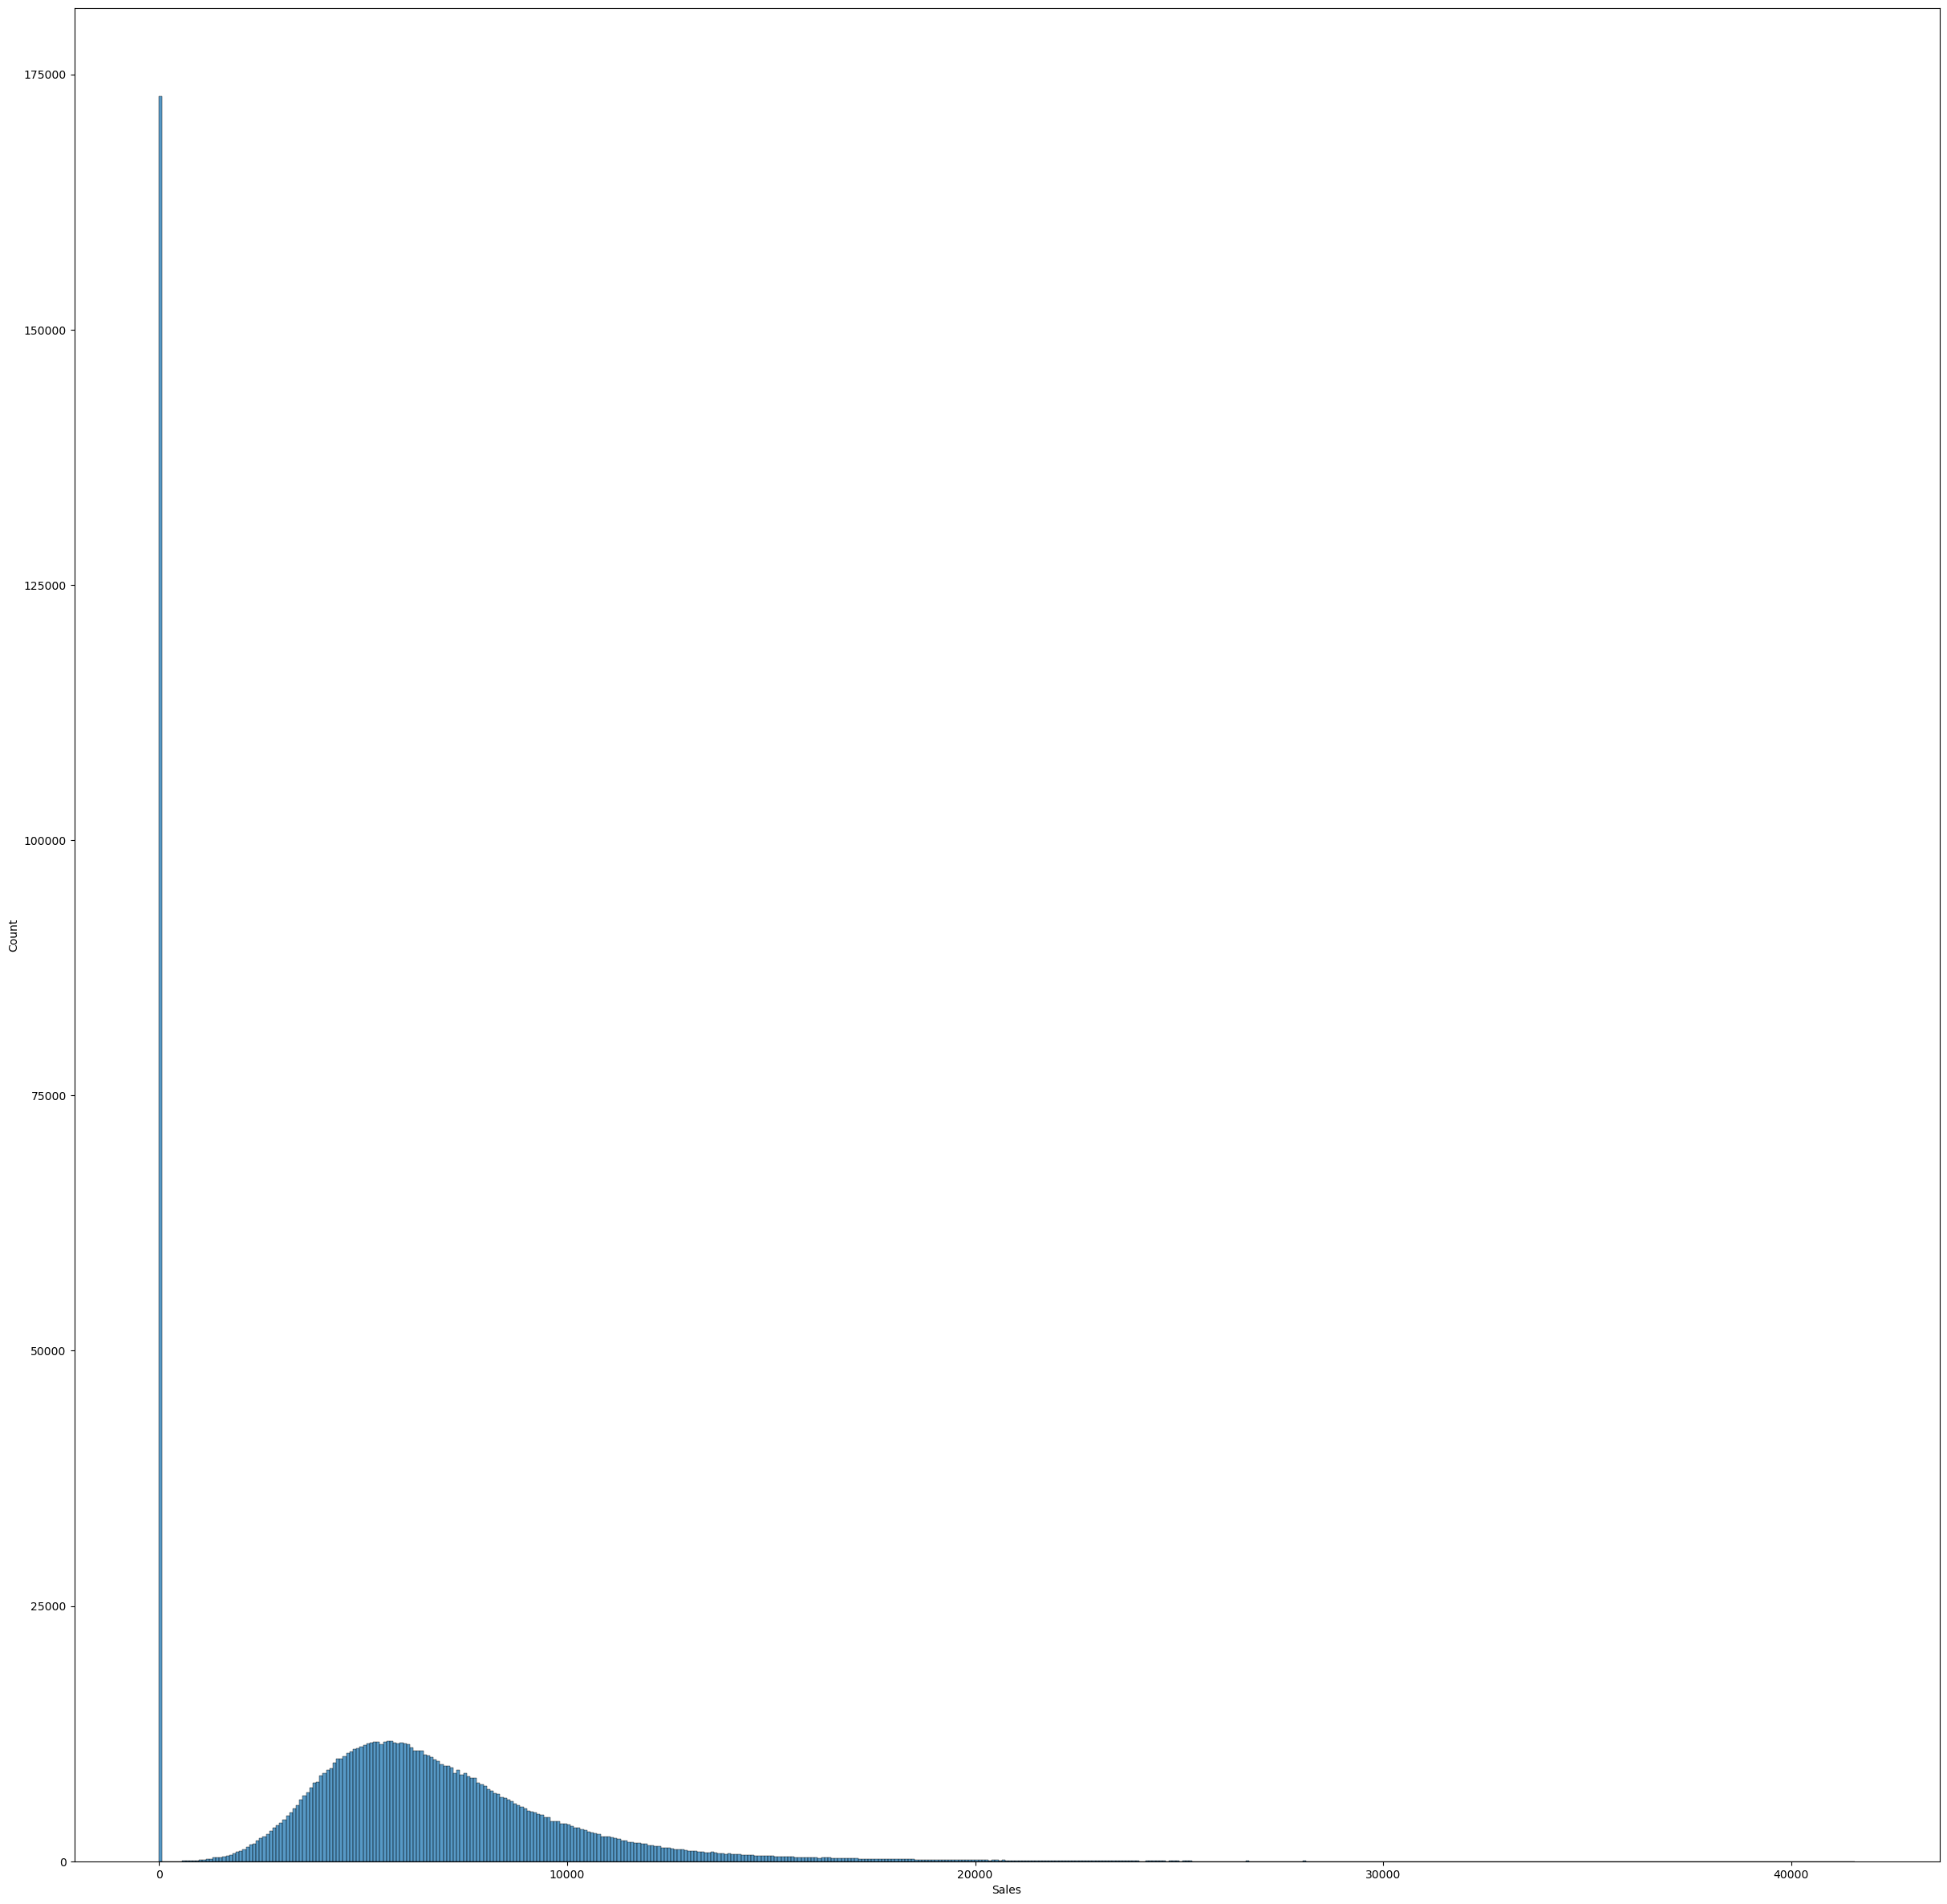

In [117]:
import plotly.express as px 
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.histplot(data=merged_df, x='Sales')

In [118]:
print(merged_df[merged_df['Sales'] == 0]['Open'].value_counts())
#meaning that sale = 0 with open = no is 172817 and open = yes is 54

Open
0    172817
1        54
Name: count, dtype: int64


In [119]:
print(pd.crosstab(merged_df['DayOfWeek'], merged_df['Open']))

Open            0       1
DayOfWeek                
1            7170  137560
2            1703  143961
3            3729  141936
4           11201  134644
5            7205  138640
6             672  144058
7          141137    3593


In [120]:
merged_df = merged_df[(merged_df['Sales'] > 0) & (merged_df['Open'] == 1)].copy()

In [121]:
print(pd.crosstab(merged_df['DayOfWeek'], merged_df['Open'])) #The reason that we drop the sales = 0 and open = 1 is that it is a very small number of rows (54) and it is likely that these are data entry errors.

Open            1
DayOfWeek        
1          137557
2          143955
3          141922
4          134626
5          138633
6          144052
7            3593


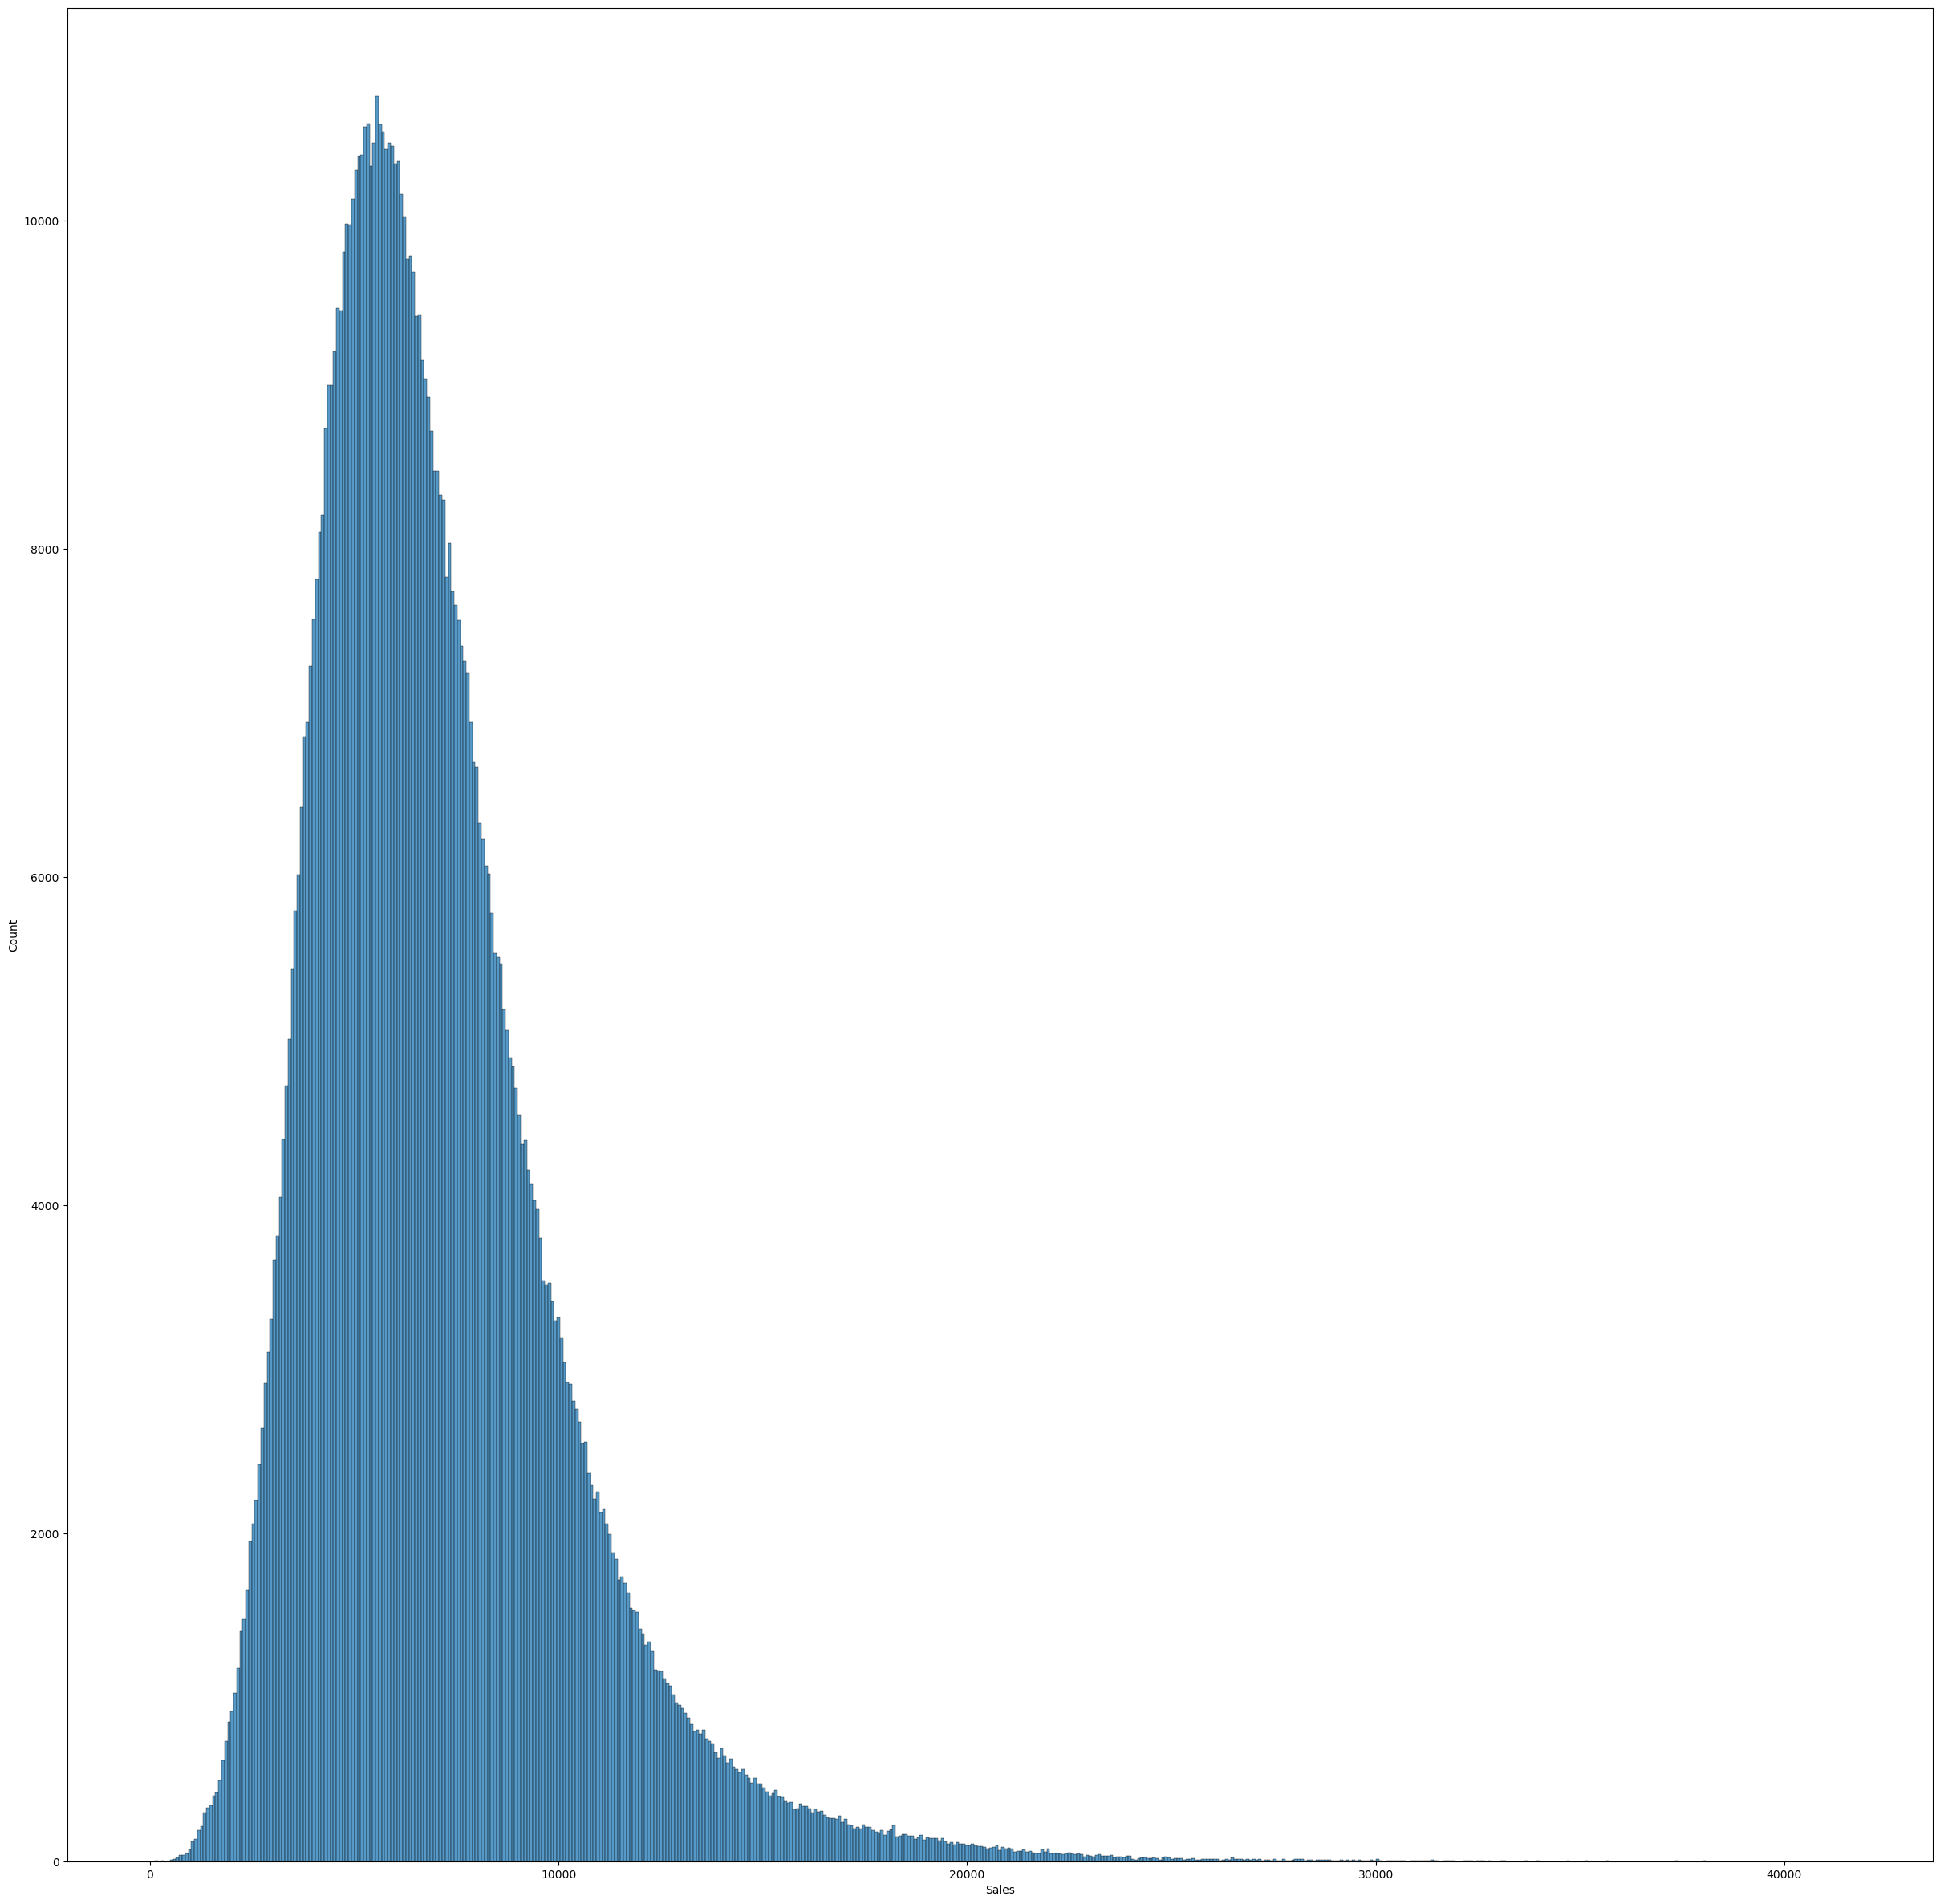

In [122]:
sns.histplot(data=merged_df, x='Sales');

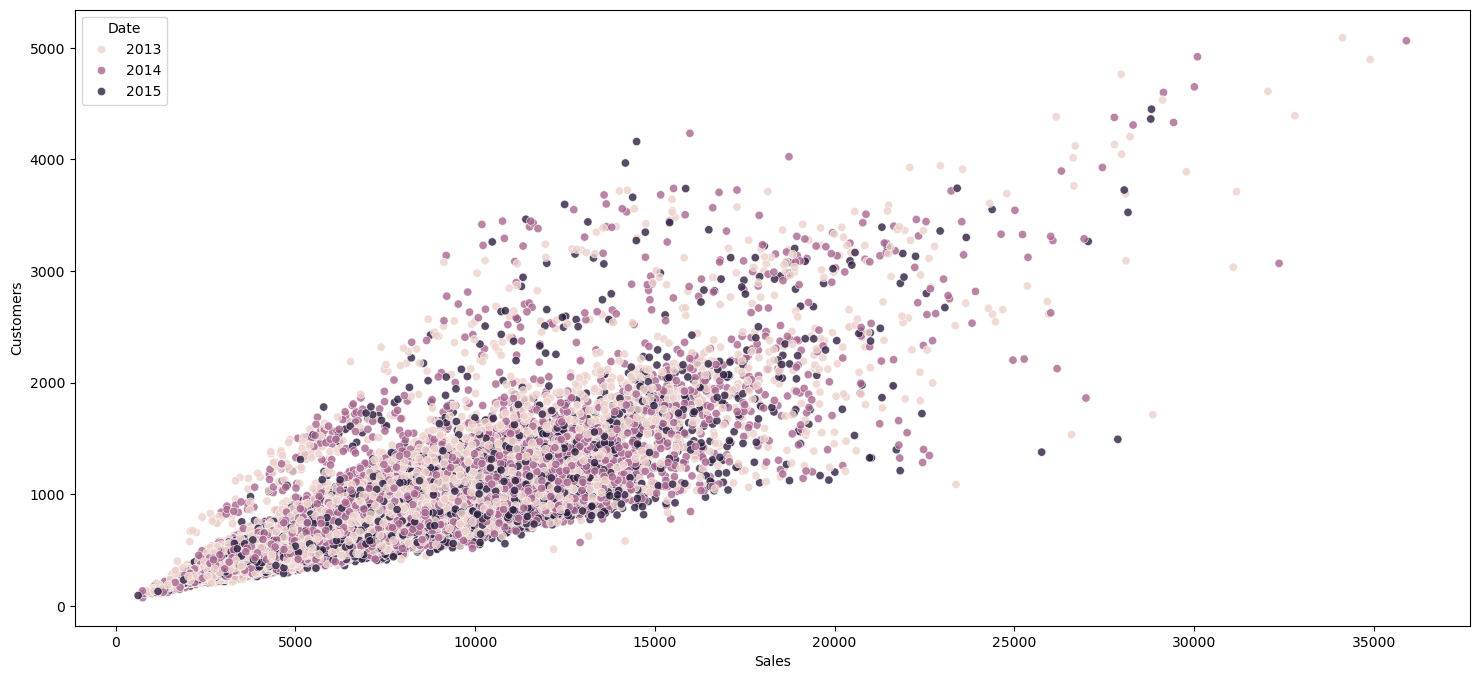

In [123]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(40000)
sns.scatterplot(x=temp_df.Sales, y =temp_df.Customers, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs Customers')
plt.show()

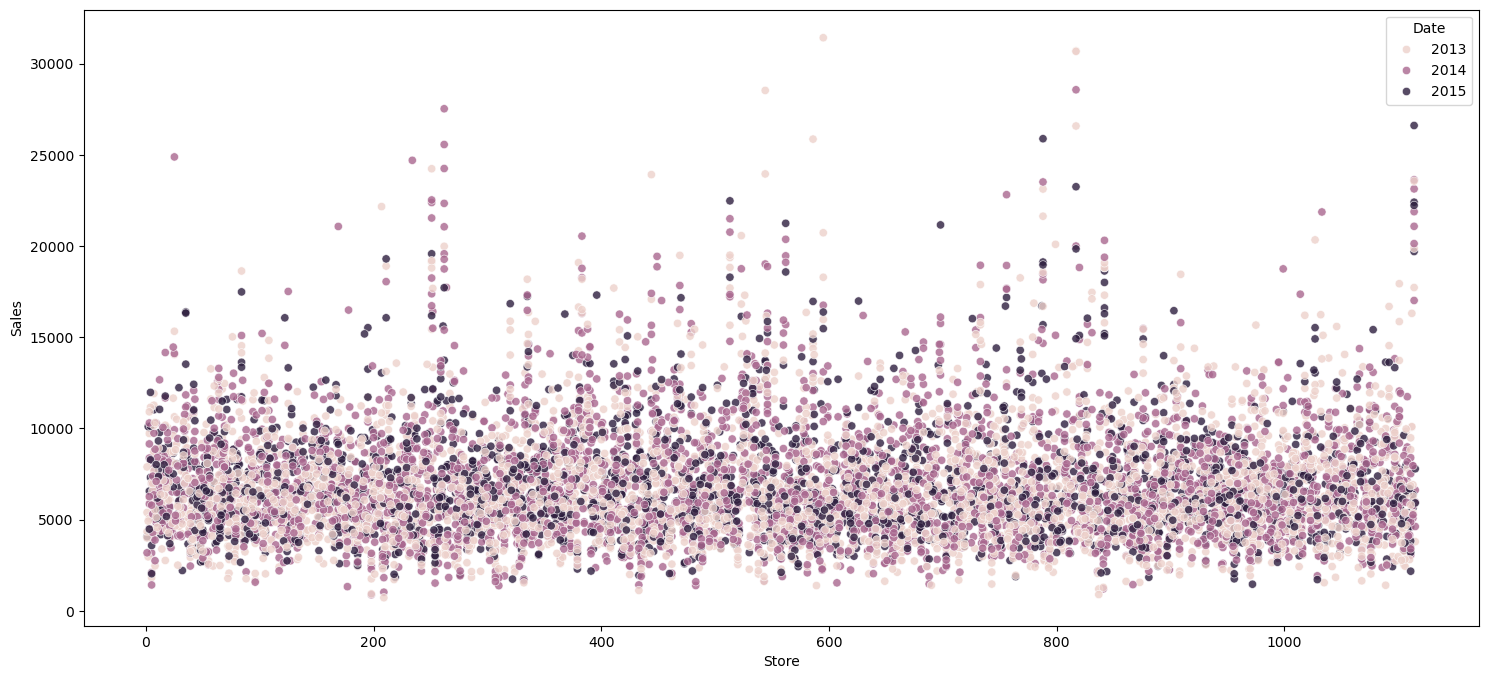

In [124]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(10000)
sns.scatterplot(x=temp_df.Store, y =temp_df.Sales, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs Store')
plt.show()

In [125]:
merged_df.corr(numeric_only=True)['Sales'].sort_values(ascending=False)
#how to read the results: the correlation coefficient is a number between -1 and 1. A positive correlation means that as one variable increases, the other variable tends to increase as well. A negative correlation means that as one variable increases, the other variable tends to decrease. A correlation of 0 means there is no linear relationship between the two variables.

Sales                        1.000000
Customers                    0.823552
Promo                        0.368199
Promo2SinceWeek              0.095212
SchoolHoliday                0.038635
CompetitionOpenSinceYear     0.016102
Store                        0.007723
Promo2SinceYear             -0.034595
CompetitionDistance         -0.036453
CompetitionOpenSinceMonth   -0.043472
Promo2                      -0.127556
DayOfWeek                   -0.178753
Open                              NaN
Name: Sales, dtype: float64

In [126]:
def split_date(df):
    df['Date'] = pd.to_datetime(df['Date'])
    df['Year'] = df.Date.dt.year
    df['Month'] = df.Date.dt.month
    df['Day'] = df.Date.dt.day
    df['WeekOfYear'] = df.Date.dt.isocalendar().week.astype(int)
split_date(merged_df)
split_date(merged_test_df)

In [127]:
merged_test_df['Day'] = merged_test_df.Date.dt.day
merged_test_df['Month'] = merged_test_df.Date.dt.month
merged_test_df['Year'] = merged_test_df.Date.dt.year

<Axes: xlabel='Year', ylabel='Sales'>

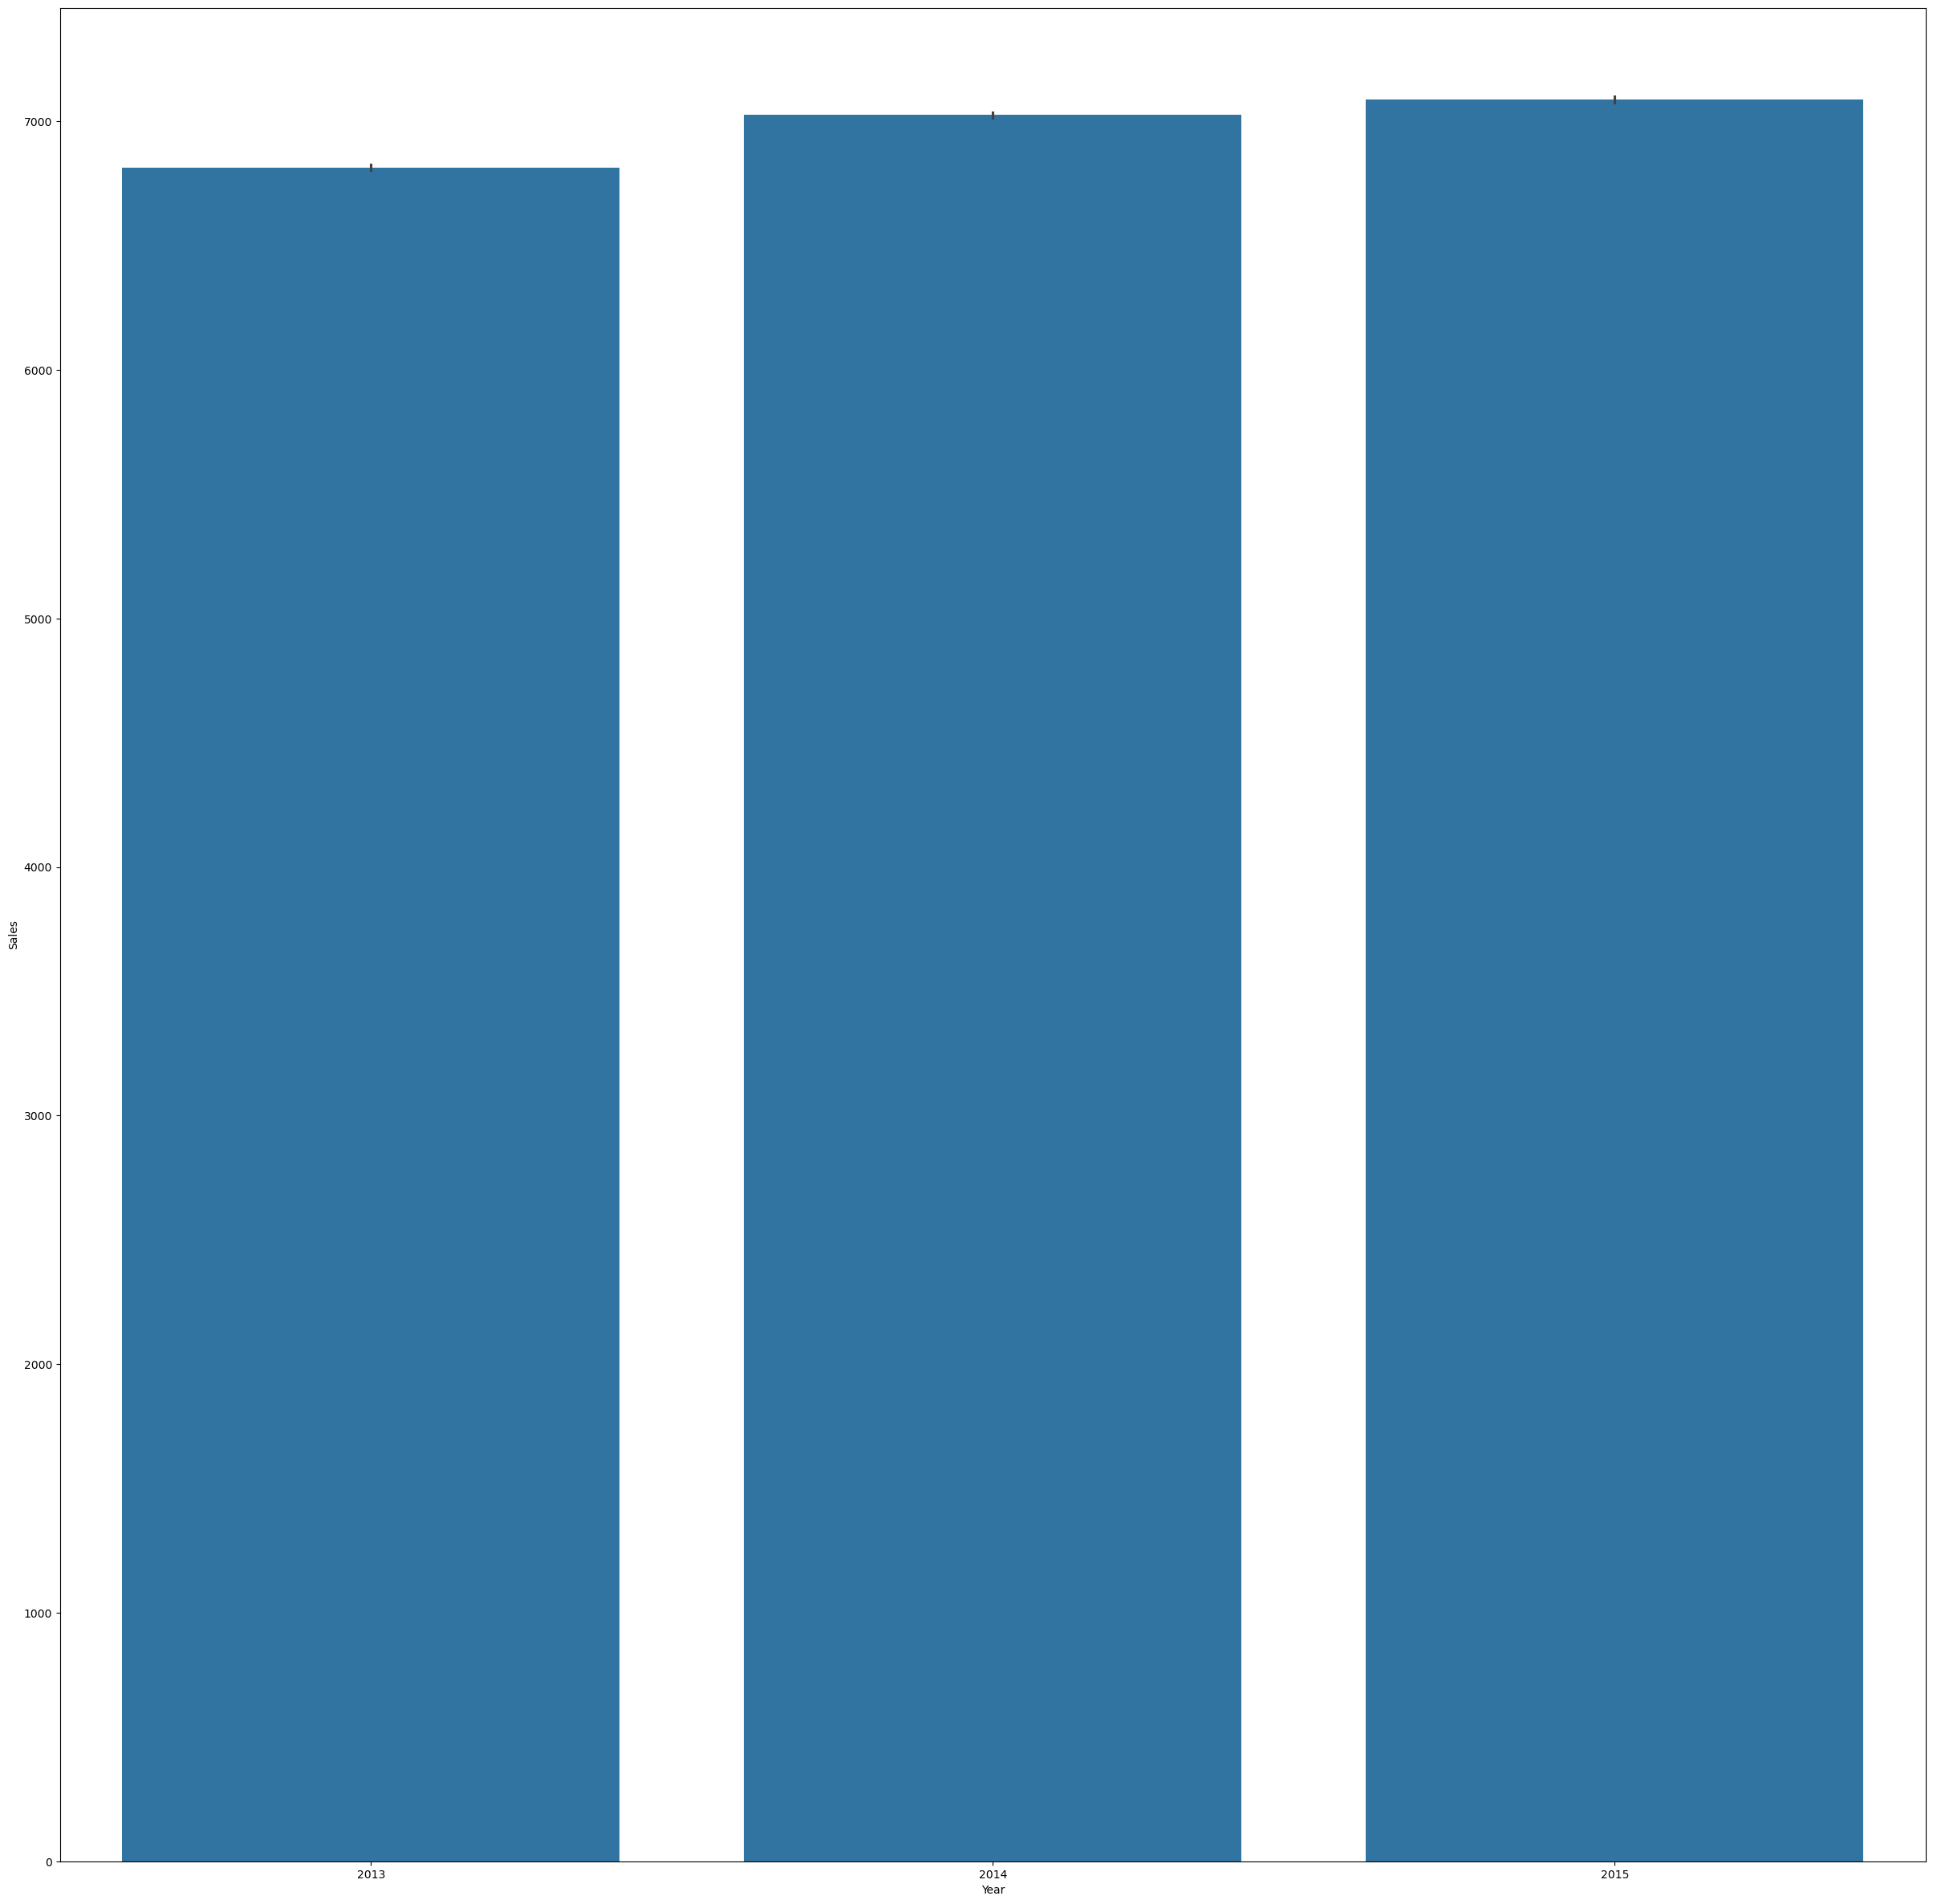

In [128]:
sns.barplot(merged_df, y= 'Sales', x = 'Year')

In [129]:
merged_df = merged_df[(merged_df['Sales'] > 0) & (merged_df['Open'] == 1)].copy()

<Axes: xlabel='Month', ylabel='Sales'>

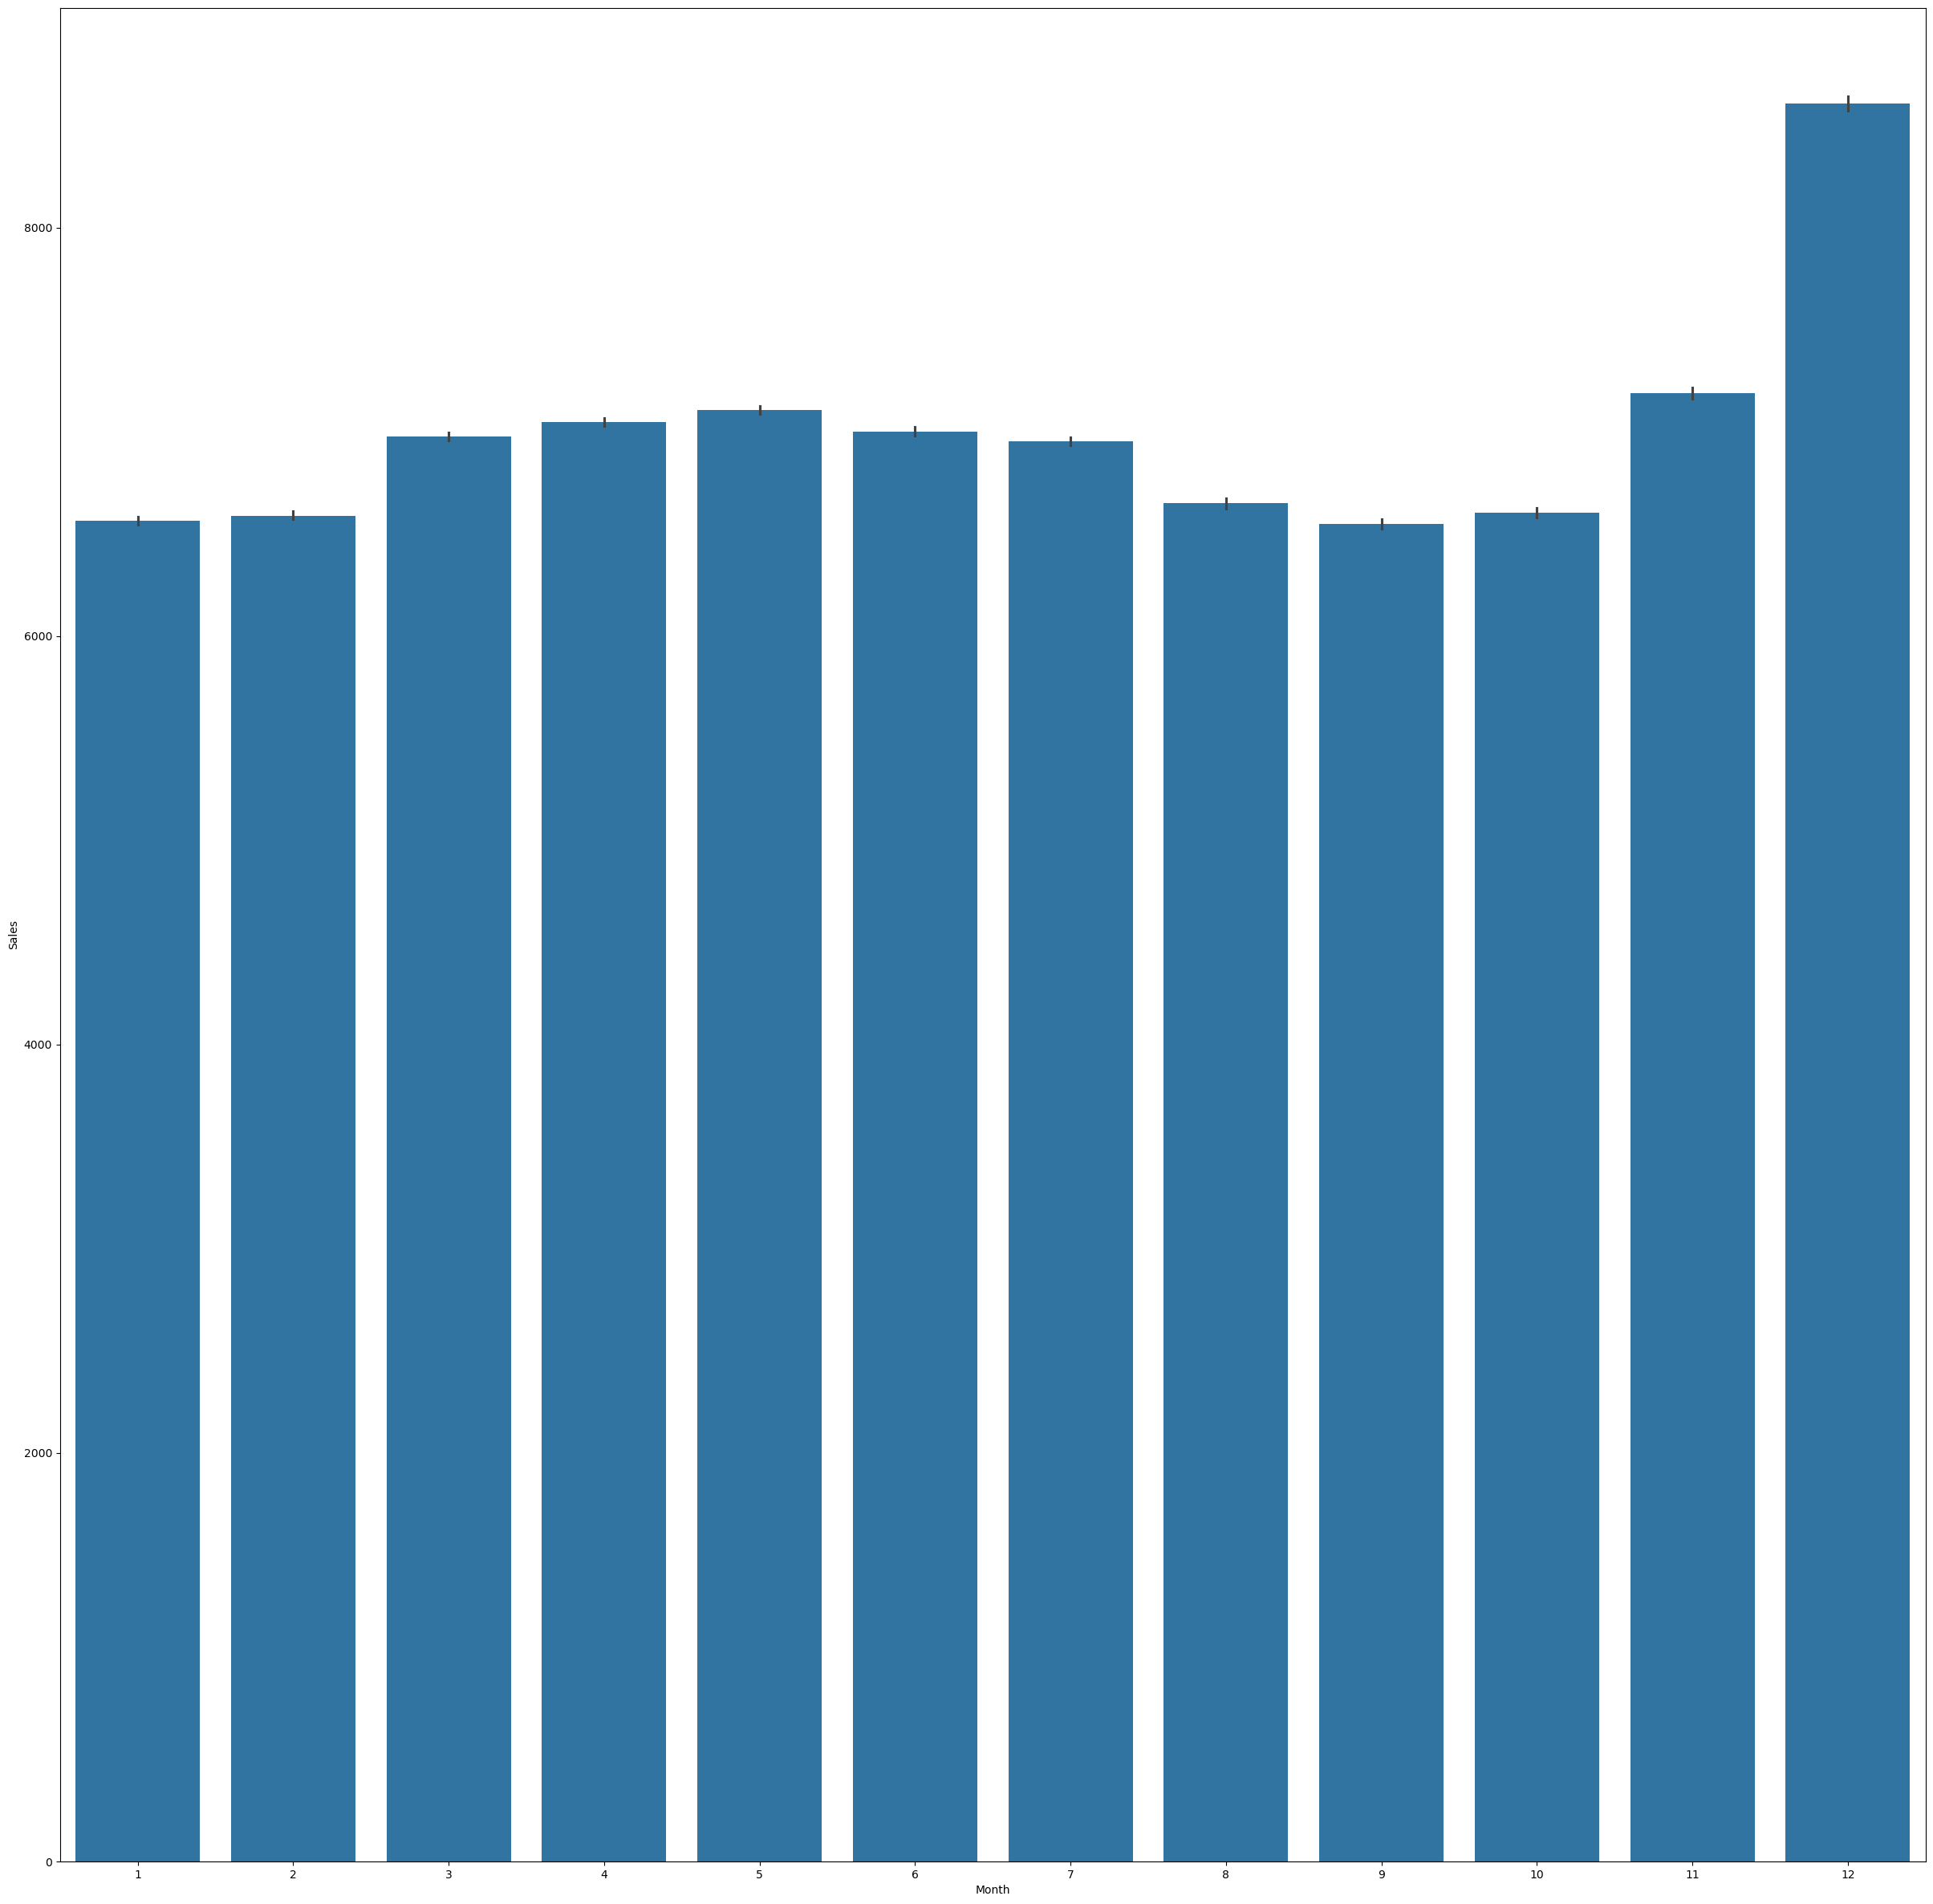

In [130]:
sns.barplot(data=merged_df, x='Month', y='Sales')

In [131]:
%pip install holidays

Note: you may need to restart the kernel to use updated packages.


In [132]:
import holidays
#Get all German public holidays for each year present in the dataset
# #use unique year in that
merged_df['Date']= pd.to_datetime(merged_df['Date'])
public_holiday = holidays.Germany(years=merged_df['Year'].unique())
#now time to create a new column with public holiday or not
merged_df['is_Public_holiday'] = merged_df['Date'].dt.date.isin(public_holiday)
#dt.date converts a Timestamp (datetime) into a Python datetime.date
merged_test_df['Date']= pd.to_datetime(merged_test_df['Date'])
merged_test_df['is_Public_holiday'] = merged_test_df['Date'].dt.date.isin(holidays.Germany(years=merged_test_df['Year'].unique()))


In [133]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear,is_Public_holiday
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,2008.0,0,NaN,NaN,NaN,2015,7,31,31,False
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,31,False
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,31,False
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,2009.0,0,NaN,NaN,NaN,2015,7,31,31,False
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,2015.0,0,NaN,NaN,NaN,2015,7,31,31,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,2006.0,0,NaN,NaN,NaN,2013,1,1,1,True
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,1999.0,0,NaN,NaN,NaN,2013,1,1,1,True
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct",2013,1,1,1,True
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,NaN,0,NaN,NaN,NaN,2013,1,1,1,True


In [134]:
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear,is_Public_holiday
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,...,2008.0,0,NaN,NaN,NaN,2015,9,17,38,False
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,...,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,9,17,38,False
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,...,2013.0,0,NaN,NaN,NaN,2015,9,17,38,False
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,...,2014.0,0,NaN,NaN,NaN,2015,9,17,38,False
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,...,2000.0,0,NaN,NaN,NaN,2015,9,17,38,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,...,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct",2015,8,1,31,False
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,...,2006.0,0,NaN,NaN,NaN,2015,8,1,31,False
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,...,NaN,0,NaN,NaN,NaN,2015,8,1,31,False
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,...,NaN,0,NaN,NaN,NaN,2015,8,1,31,False


In [135]:
merged_test_df['is_Public_holiday'].value_counts()

is_Public_holiday
False    41088
Name: count, dtype: int64

In [136]:
merged_df['is_Public_holiday'].value_counts()

is_Public_holiday
False    843739
True        599
Name: count, dtype: int64

In [137]:
merged_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Year', 'Month', 'Day',
       'WeekOfYear', 'is_Public_holiday'],
      dtype='object')

In [138]:
#The features Promo2, Promo2SinceWeek etc. are not very useful in their current form, because they do not relate to the current date. How can you improve their representation?
#Summary to find if promo2 still active until that specific date 
#Solution: 
#1. check if promo2 is available or not
#2. check if promoInterval is corrected or not(if that day(Date column) are not in range of PromoInterval , it means no promo2 actived on that date)
#3. check if Promo2SinceYear is corrected or not (if it is null or it is later that that day(date column) , it means false)
#4. same as #3 but check more if Promo2SinceYear and Date Column are in the same date but weeks-th of Date Column is smaller than PromoSinceYear's , there is no way it could happen, so false
#If they can cross all those, it mean is_activePromo is 1 


#we map from 1 : 3chars
month_map = {
   1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sept', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
#add one more column in dataset. that column is 3 chars Month
merged_df['MonthStr'] = merged_df['Date'].dt.month.map(month_map)
merged_test_df['MonthStr'] = merged_test_df['Date'].dt.month.map(month_map)

def is_promo2_active(row) : 
  if(row['Promo2']) ==0: 
    return 0
  if pd.isna(row['PromoInterval']):
    return 0
  active_months = row['PromoInterval'].split(',')
  if row['MonthStr'] not in active_months:
    return 0
  row_year, row_week, _ = row['Date'].isocalendar()
  if pd.isna(row['Promo2SinceYear']):
    return 0
  if row_year < row['Promo2SinceYear']:
    return 0
  if row_year == row['Promo2SinceYear'] and row_week <row['Promo2SinceWeek']:
    return 0
  
  return 1
# Apply the is_promo2_active() function to EVERY row in merged_df (axis=1 means "row-wise"),
# and store the resulting 0/1 values in a new column called 'IsPromo2Active'

def promo_col(df):
    df['IsPromo2Active'] = df.apply(is_promo2_active, axis=1)
    df['Num_months_Promo2Open'] = 12 * (df.Year - df.Promo2SinceYear) + (df.WeekOfYear - df.Promo2SinceWeek) * 7 / 30.5
    df['Promo2Open'] = df['Num_months_Promo2Open'].map(lambda x: 0 if x < 0 else x).fillna(0) * df['Promo2']

promo_col(merged_df)
promo_col(merged_test_df)



In [139]:
def comp_months(df):
    df['Num_Month_CompetitionOpen'] = 12 * (df.Year - df.CompetitionOpenSinceYear) + (df.Month - df.CompetitionOpenSinceMonth)
    df['Num_Month_CompetitionOpen'] = df['Num_Month_CompetitionOpen'].map(lambda x: 0 if x < 0 else x).fillna(0)
comp_months(merged_df)
comp_months(merged_test_df)

In [140]:
merged_df['HasCompetition'] = merged_df['Num_Month_CompetitionOpen'].notna().astype(int)
merged_test_df['HasCompetition'] = merged_test_df['Num_Month_CompetitionOpen'].notna().astype(int)


In [141]:
#make it very far (no, just to make it very far away)
merged_df['Up_CompetitionDistance'] = merged_df['CompetitionDistance'].fillna(merged_df['CompetitionDistance'].max() * 3)
merged_test_df['Up_CompetitionDistance'] = merged_test_df['CompetitionDistance'].fillna(merged_df['CompetitionDistance'].max() * 3)
#just to make it very far away

In [142]:
import numpy as np
merged_df['CompetitionDistanceBucket'] = pd.cut(
  merged_df['Up_CompetitionDistance'],
  bins = [0, 1000, 5000, 20000, np.inf],
  labels = ['very_close', 'close', 'moderate', 'far']
)
merged_test_df['CompetitionDistanceBucket'] = pd.cut(
  merged_test_df['Up_CompetitionDistance'],
  bins = [0, 1000, 5000, 20000, np.inf],
  labels = ['very_close', 'close', 'moderate', 'far']
)

In [143]:
sept = merged_df[(merged_df['MonthStr'] == 'Sept') &
                 (merged_df['PromoInterval'].str.contains('Sept', na=False)) &
                 (merged_df['Promo2'] == 1)]
print(sept['IsPromo2Active'].value_counts())

IsPromo2Active
1    4361
0     703
Name: count, dtype: int64


In [144]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,WeekOfYear,is_Public_holiday,MonthStr,IsPromo2Active,Num_months_Promo2Open,Promo2Open,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,31,False,Jul,0,NaN,0.000000,82.0,1,1270.0,close
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,31,False,Jul,1,64.131148,64.131148,92.0,1,570.0,very_close
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,31,False,Jul,1,51.901639,51.901639,103.0,1,14130.0,moderate
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,31,False,Jul,0,NaN,0.000000,70.0,1,620.0,very_close
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,31,False,Jul,0,NaN,0.000000,3.0,1,29910.0,far
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,1,True,Jan,0,NaN,0.000000,76.0,1,150.0,very_close
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,1,True,Jan,0,NaN,0.000000,159.0,1,860.0,very_close
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,1,True,Jan,1,1.213115,1.213115,0.0,1,840.0,very_close
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,1,True,Jan,0,NaN,0.000000,0.0,1,1430.0,close


In [145]:
merged_df[['CompetitionOpenSinceYear', 'Num_Month_CompetitionOpen', 'HasCompetition', 'CompetitionDistance', 'Up_CompetitionDistance', 'CompetitionDistanceBucket']]

,CompetitionOpenSinceYear,Num_Month_CompetitionOpen,HasCompetition,CompetitionDistance,Up_CompetitionDistance,CompetitionDistanceBucket
0,2008.0,82.0,1,1270.0,1270.0,close
1,2007.0,92.0,1,570.0,570.0,very_close
2,2006.0,103.0,1,14130.0,14130.0,moderate
3,2009.0,70.0,1,620.0,620.0,very_close
4,2015.0,3.0,1,29910.0,29910.0,far
...,...,...,...,...,...,...
1016776,2006.0,76.0,1,150.0,150.0,very_close
1016827,1999.0,159.0,1,860.0,860.0,very_close
1016863,NaN,0.0,1,840.0,840.0,very_close
1017042,NaN,0.0,1,1430.0,1430.0,close


In [146]:
merged_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Year', 'Month', 'Day',
       'WeekOfYear', 'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_months_Promo2Open', 'Promo2Open', 'Num_Month_CompetitionOpen',
       'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket'],
      dtype='object')

In [147]:
input_cols = ['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday', 
              'StoreType', 'Assortment', 'CompetitionDistance', 'Num_Month_CompetitionOpen', 
              'Day', 'Month', 'Year', 'WeekOfYear',  'Promo2', 
              'Promo2Open', 'IsPromo2Active']
target_col = ['Sales']

In [148]:
merged_df = merged_df.sort_values('Date').reset_index(drop=True)

cutoff = merged_df['Date'].max() - pd.Timedelta(days=48)

train_df = merged_df[(merged_df['Date'] <= cutoff) & (merged_df['Open'] == 1)].copy()
val_df   = merged_df[(merged_df['Date'] >  cutoff) & (merged_df['Open'] == 1)].copy()

print(train_df['Date'].max(), val_df['Date'].min())   # no overlap
print(len(train_df), len(val_df))

2015-06-13 00:00:00 2015-06-14 00:00:00
798454 45884


In [149]:
merged_df['Promo2Open']

0          0.000000
1          0.000000
2          0.000000
3          0.000000
4          0.000000
            ...    
844333    70.622951
844334    47.081967
844335     0.000000
844336     0.000000
844337     0.000000
Name: Promo2Open, Length: 844338, dtype: float64

In [150]:
train_inputs = train_df[input_cols].copy()
train_targets = train_df[target_col].copy()

In [151]:
val_inputs = val_df[input_cols].copy()
val_targets = val_df[target_col].copy()

In [152]:
test_inputs = merged_test_df[input_cols].copy()
#data does not have target column, so we do not need to create test_targets

In [153]:
train_inputs

,Store,DayOfWeek,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Num_Month_CompetitionOpen,Day,Month,Year,WeekOfYear,Promo2,Promo2Open,IsPromo2Active
0,1097,2,0,a,1,b,b,720.0,130.0,1,1,2013,1,0,0.000000,0
1,85,2,0,a,1,b,a,1870.0,15.0,1,1,2013,1,0,0.000000,0
2,259,2,0,a,1,b,b,210.0,0.0,1,1,2013,1,0,0.000000,0
3,262,2,0,a,1,b,a,1180.0,0.0,1,1,2013,1,0,0.000000,0
4,274,2,0,a,1,b,b,3640.0,0.0,1,1,2013,1,1,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
798449,746,6,0,0,0,d,c,4330.0,52.0,13,6,2015,24,1,45.475410,1
798450,747,6,0,0,0,c,c,45740.0,82.0,13,6,2015,24,0,0.000000,0
798451,748,6,0,0,0,d,a,2380.0,63.0,13,6,2015,24,1,50.295082,0
798452,749,6,0,0,0,a,a,3410.0,46.0,13,6,2015,24,1,2.295082,0


In [154]:
train_inputs.columns

Index(['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
       'StoreType', 'Assortment', 'CompetitionDistance',
       'Num_Month_CompetitionOpen', 'Day', 'Month', 'Year', 'WeekOfYear',
       'Promo2', 'Promo2Open', 'IsPromo2Active'],
      dtype='object')

In [155]:
train_inputs

,Store,DayOfWeek,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Num_Month_CompetitionOpen,Day,Month,Year,WeekOfYear,Promo2,Promo2Open,IsPromo2Active
0,1097,2,0,a,1,b,b,720.0,130.0,1,1,2013,1,0,0.000000,0
1,85,2,0,a,1,b,a,1870.0,15.0,1,1,2013,1,0,0.000000,0
2,259,2,0,a,1,b,b,210.0,0.0,1,1,2013,1,0,0.000000,0
3,262,2,0,a,1,b,a,1180.0,0.0,1,1,2013,1,0,0.000000,0
4,274,2,0,a,1,b,b,3640.0,0.0,1,1,2013,1,1,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
798449,746,6,0,0,0,d,c,4330.0,52.0,13,6,2015,24,1,45.475410,1
798450,747,6,0,0,0,c,c,45740.0,82.0,13,6,2015,24,0,0.000000,0
798451,748,6,0,0,0,d,a,2380.0,63.0,13,6,2015,24,1,50.295082,0
798452,749,6,0,0,0,a,a,3410.0,46.0,13,6,2015,24,1,2.295082,0


In [156]:
test_inputs

,Store,DayOfWeek,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,Num_Month_CompetitionOpen,Day,Month,Year,WeekOfYear,Promo2,Promo2Open,IsPromo2Active
0,1,4,1,0,0,c,a,1270.0,84.0,17,9,2015,38,0,0.000000,0
1,3,4,1,0,0,a,a,14130.0,105.0,17,9,2015,38,1,53.508197,0
2,7,4,1,0,0,a,c,24000.0,29.0,17,9,2015,38,0,0.000000,0
3,8,4,1,0,0,a,a,7520.0,11.0,17,9,2015,38,0,0.000000,0
4,9,4,1,0,0,a,c,2030.0,181.0,17,9,2015,38,0,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,1111,6,0,0,0,a,a,1900.0,14.0,1,8,2015,31,1,24.000000,0
41084,1112,6,0,0,0,c,c,1880.0,112.0,1,8,2015,31,0,0.000000,0
41085,1113,6,0,0,0,a,c,9260.0,0.0,1,8,2015,31,0,0.000000,0
41086,1114,6,0,0,0,a,c,870.0,0.0,1,8,2015,31,0,0.000000,0


In [157]:
#numeric_cols is to get all the numeric columns in the train_inputs dataframe, and categorical_cols is to get all the categorical columns in the train_inputs dataframe. This is useful for preprocessing steps, such as scaling numeric features or encoding categorical features before training a machine learning model.
#catorical_cols is to get all the categorical columns in the train_inputs dataframe. This is useful for preprocessing steps, such as scaling numeric features or encoding categorical features before training a machine learning model.
numeric_cols = ['Store', 'Promo', 'SchoolHoliday', 
              'CompetitionDistance', 'Num_Month_CompetitionOpen', 'Promo2', 'Promo2Open', 'IsPromo2Active',
              'Day', 'Month', 'Year', 'WeekOfYear',  ]
categorical_cols = ['DayOfWeek', 'StateHoliday', 'StoreType', 'Assortment']

In [158]:
train_inputs[numeric_cols]

,Store,Promo,SchoolHoliday,CompetitionDistance,Num_Month_CompetitionOpen,Promo2,Promo2Open,IsPromo2Active,Day,Month,Year,WeekOfYear
0,1097,0,1,720.0,130.0,0,0.000000,0,1,1,2013,1
1,85,0,1,1870.0,15.0,0,0.000000,0,1,1,2013,1
2,259,0,1,210.0,0.0,0,0.000000,0,1,1,2013,1
3,262,0,1,1180.0,0.0,0,0.000000,0,1,1,2013,1
4,274,0,1,3640.0,0.0,1,0.000000,0,1,1,2013,1
...,...,...,...,...,...,...,...,...,...,...,...,...
798449,746,0,0,4330.0,52.0,1,45.475410,1,13,6,2015,24
798450,747,0,0,45740.0,82.0,0,0.000000,0,13,6,2015,24
798451,748,0,0,2380.0,63.0,1,50.295082,0,13,6,2015,24
798452,749,0,0,3410.0,46.0,1,2.295082,0,13,6,2015,24


In [159]:
val_inputs[numeric_cols]

,Store,Promo,SchoolHoliday,CompetitionDistance,Num_Month_CompetitionOpen,Promo2,Promo2Open,IsPromo2Active,Day,Month,Year,WeekOfYear
798454,453,0,0,75860.0,0.0,0,0.000000,0,14,6,2015,24
798455,433,0,0,30030.0,55.0,0,0.000000,0,14,6,2015,24
798456,423,0,0,1270.0,13.0,0,0.000000,0,14,6,2015,24
798457,353,0,0,900.0,0.0,1,26.295082,0,14,6,2015,24
798458,335,0,0,90.0,0.0,1,22.393443,0,14,6,2015,24
...,...,...,...,...,...,...,...,...,...,...,...,...
844333,745,1,1,17650.0,20.0,1,70.622951,1,31,7,2015,31
844334,746,1,1,4330.0,53.0,1,47.081967,0,31,7,2015,31
844335,747,1,1,45740.0,83.0,0,0.000000,0,31,7,2015,31
844336,741,1,1,11900.0,0.0,0,0.000000,0,31,7,2015,31


In [160]:
train_inputs[categorical_cols]

,DayOfWeek,StateHoliday,StoreType,Assortment
0,2,a,b,b
1,2,a,b,a
2,2,a,b,b
3,2,a,b,a
4,2,a,b,b
...,...,...,...,...
798449,6,0,d,c
798450,6,0,c,c
798451,6,0,d,a
798452,6,0,a,a


In [161]:
#now start working on Numeric columns, we can apply scaling or normalization techniques to ensure that all numeric features are on a similar scale. This can help improve the performance of machine learning models. For categorical columns, we can apply encoding techniques such as one-hot 
test_inputs[numeric_cols].isna().sum()
#only competition distance has 0.5% missing values, we can fill it with median or mean value of that column, or we can fill it with a very far away value to indicate that there is no competition nearby. We can also create a new column to indicate whether there is competition nearby or not. This way, the model can learn that if there is no competition nearby, the sales will be higher.

Store                         0
Promo                         0
SchoolHoliday                 0
CompetitionDistance          96
Num_Month_CompetitionOpen     0
Promo2                        0
Promo2Open                    0
IsPromo2Active                0
Day                           0
Month                         0
Year                          0
WeekOfYear                    0
dtype: int64

In [162]:
max_distance = train_inputs.CompetitionDistance.max()

In [163]:
train_inputs['CompetitionDistance'].fillna(max_distance, inplace=True)
test_inputs['CompetitionDistance'].fillna(max_distance, inplace=True)
val_inputs['CompetitionDistance'].fillna(max_distance, inplace=True)


C:\Users\User\AppData\Local\Temp\ipykernel_29960\2679612973.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_inputs['CompetitionDistance'].fillna(max_distance, inplace=True)
C:\Users\User\AppData\Local\Temp\ipykernel_29960\2679612973.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves

In [164]:
train_inputs[numeric_cols].isna().sum()

Store                        0
Promo                        0
SchoolHoliday                0
CompetitionDistance          0
Num_Month_CompetitionOpen    0
Promo2                       0
Promo2Open                   0
IsPromo2Active               0
Day                          0
Month                        0
Year                         0
WeekOfYear                   0
dtype: int64

In [165]:
val_inputs[numeric_cols].isna().sum()

Store                        0
Promo                        0
SchoolHoliday                0
CompetitionDistance          0
Num_Month_CompetitionOpen    0
Promo2                       0
Promo2Open                   0
IsPromo2Active               0
Day                          0
Month                        0
Year                         0
WeekOfYear                   0
dtype: int64

In [166]:
#We can use techniques such as Min-Max scaling or Standardization to ensure that all numeric features are on a similar scale
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler().fit(train_inputs[numeric_cols])
train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols])
test_inputs[numeric_cols] = scaler.transform(test_inputs[numeric_cols])
val_inputs[numeric_cols] = scaler.transform(val_inputs[numeric_cols])

In [167]:
#Next, we can handle categorical features by encoding them into numerical format using techniques such as one-hot encoding or label encoding. This will allow us to use these features in machine learning models effectively.
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(train_inputs[categorical_cols])
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))
train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols])
test_inputs[encoded_cols] = encoder.transform(test_inputs[categorical_cols])
val_inputs[encoded_cols] = encoder.transform(val_inputs[categorical_cols])


In [168]:
X_train = train_inputs[numeric_cols + encoded_cols]
X_test = test_inputs[numeric_cols + encoded_cols]
X_val = val_inputs[numeric_cols + encoded_cols]

In [169]:
#Next Step is to make baseline model ,
# let create a model that always return only mean value for prediction
def return_mean_model(input):
    return np.full(len(input), merged_df['Sales'].mean())
train_predictions = return_mean_model(X_train)

In [170]:
train_predictions

array([6955.95913366, 6955.95913366, 6955.95913366, ..., 6955.95913366,
       6955.95913366, 6955.95913366], shape=(798454,))

In [171]:
#now let evaluate the RMSE
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(train_targets, return_mean_model(X_train)))
print(rmse)
# 3081 means the prices is off by 3081 on average, which is a very high error. This indicates that the baseline model is not performing well and we need to explore more sophisticated models to improve our predictions.

3104.1065056472185


In [172]:
#now random test
def guess_random(inputs):
    lo, hi = merged_df.Sales.min(), merged_df.Sales.max()
    return np.random.random(len(inputs)) * (hi - lo) + lo


In [173]:
train_preds = guess_random(X_train)
train_preds

array([ 5639.79884458, 19900.71457136, 40586.08302728, ...,
       29691.77422344, 15411.19199866,  3146.02834474], shape=(798454,))

In [174]:
rmse = np.sqrt(mean_squared_error(train_preds, train_targets))
print(rmse)
# 18569 means the prices is off by 18569 on average, which is a very high error. This indicates that the random guess model is not performing well and we need to explore more sophisticated models to improve our predictions.

18573.78482713276


In [175]:
#Baseline ML model
  #try using linear regression model to predict the sales based on the features we have engineered. We will train the model on the training set and evaluate its performance on the validation set using RMSE as our metric.

In [176]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [177]:
#Gradient Boosting
from xgboost import XGBRegressor

In [178]:
model = XGBRegressor(random_state=42, n_jobs=-1, n_estimators=20, max_depth=4)



In [179]:
model.fit(X_train, train_targets)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [180]:
preds = model.predict(X_train)
preds

array([ 9449.527 ,  9604.623 , 12648.017 , ...,  4959.776 ,  5201.0757,
        4796.652 ], shape=(798454,), dtype=float32)

In [181]:
from sklearn.metrics import mean_squared_error

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))


In [182]:
rmse(preds, train_targets)
# soo 2399 means the prices is off by 2399 on average, which is a significant improvement over the baseline model. This indicates that the XGBoost model is able to capture the underlying patterns in the data and make more accurate predictions.
# the error is 0.22, which is a significant improvement over the baseline model. This indicates that the XGBoost model is able to capture the underlying patterns in the data and make more accurate predictions.

np.float64(2358.6407102396925)

In [183]:
import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

import graphviz
print(graphviz.version())

(16, 1, 0)


In [184]:

import matplotlib.pyplot as plt
from xgboost import plot_tree
from matplotlib.pylab import rcParams
%matplotlib inline

rcParams['figure.figsize'] = 30,30

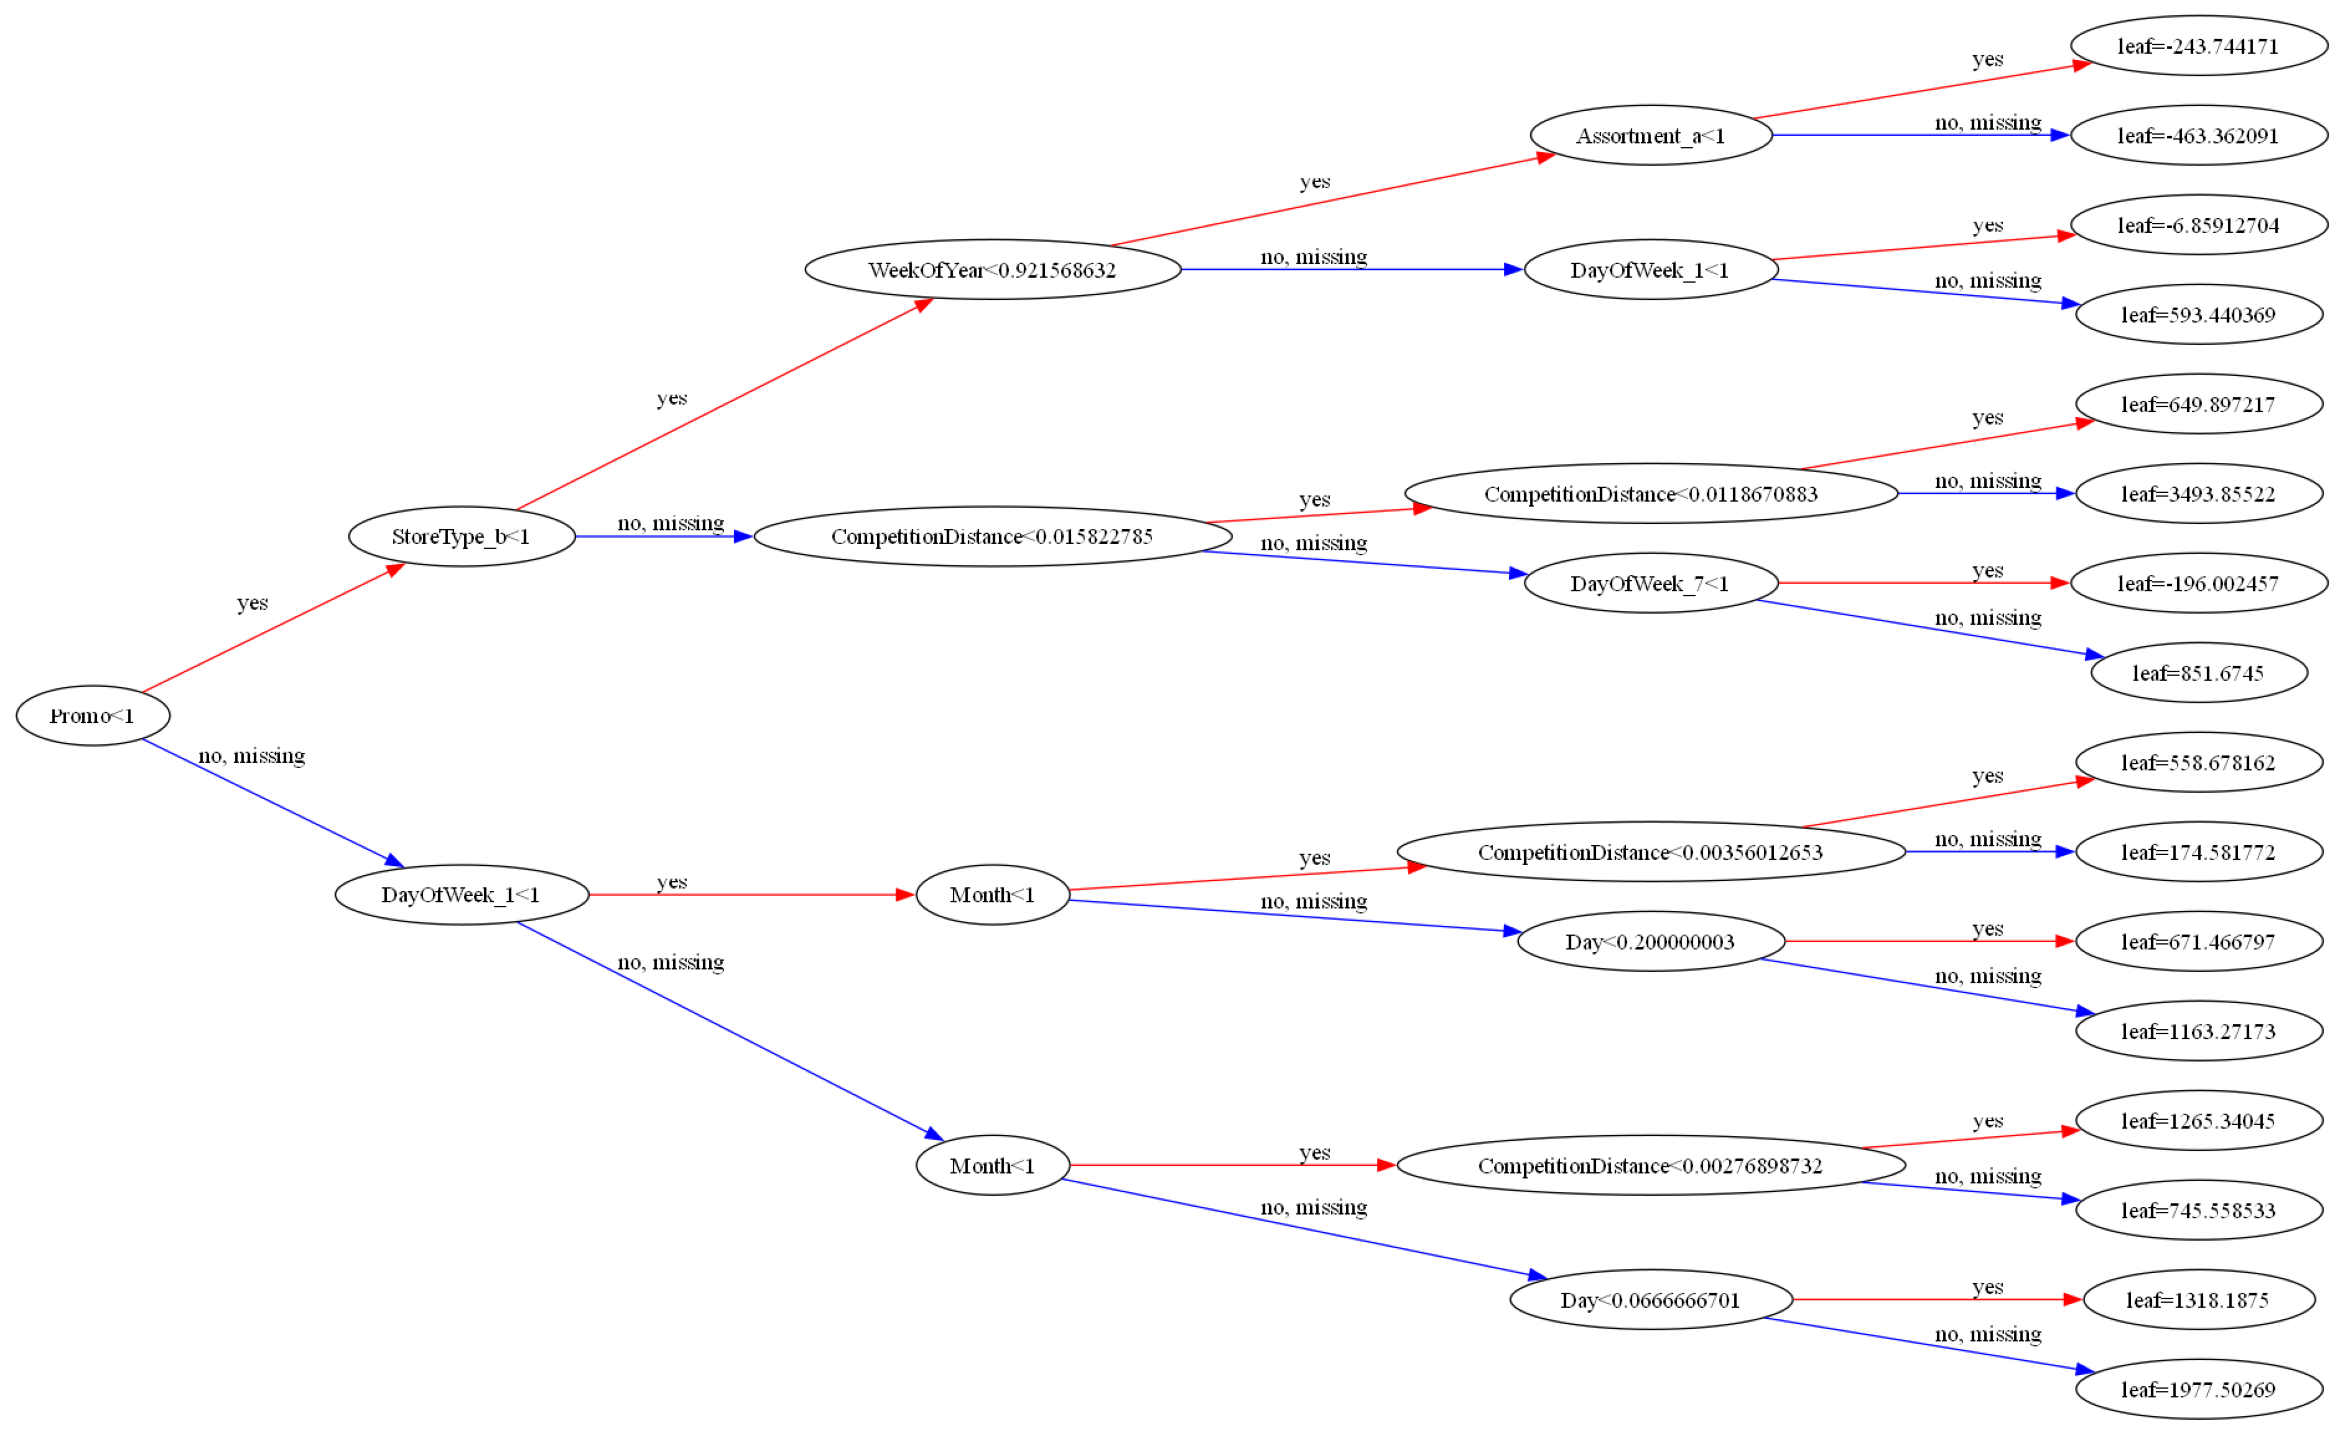

In [185]:
plot_tree(model, rankdir='LR');

d:\Machine_Learning_File\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


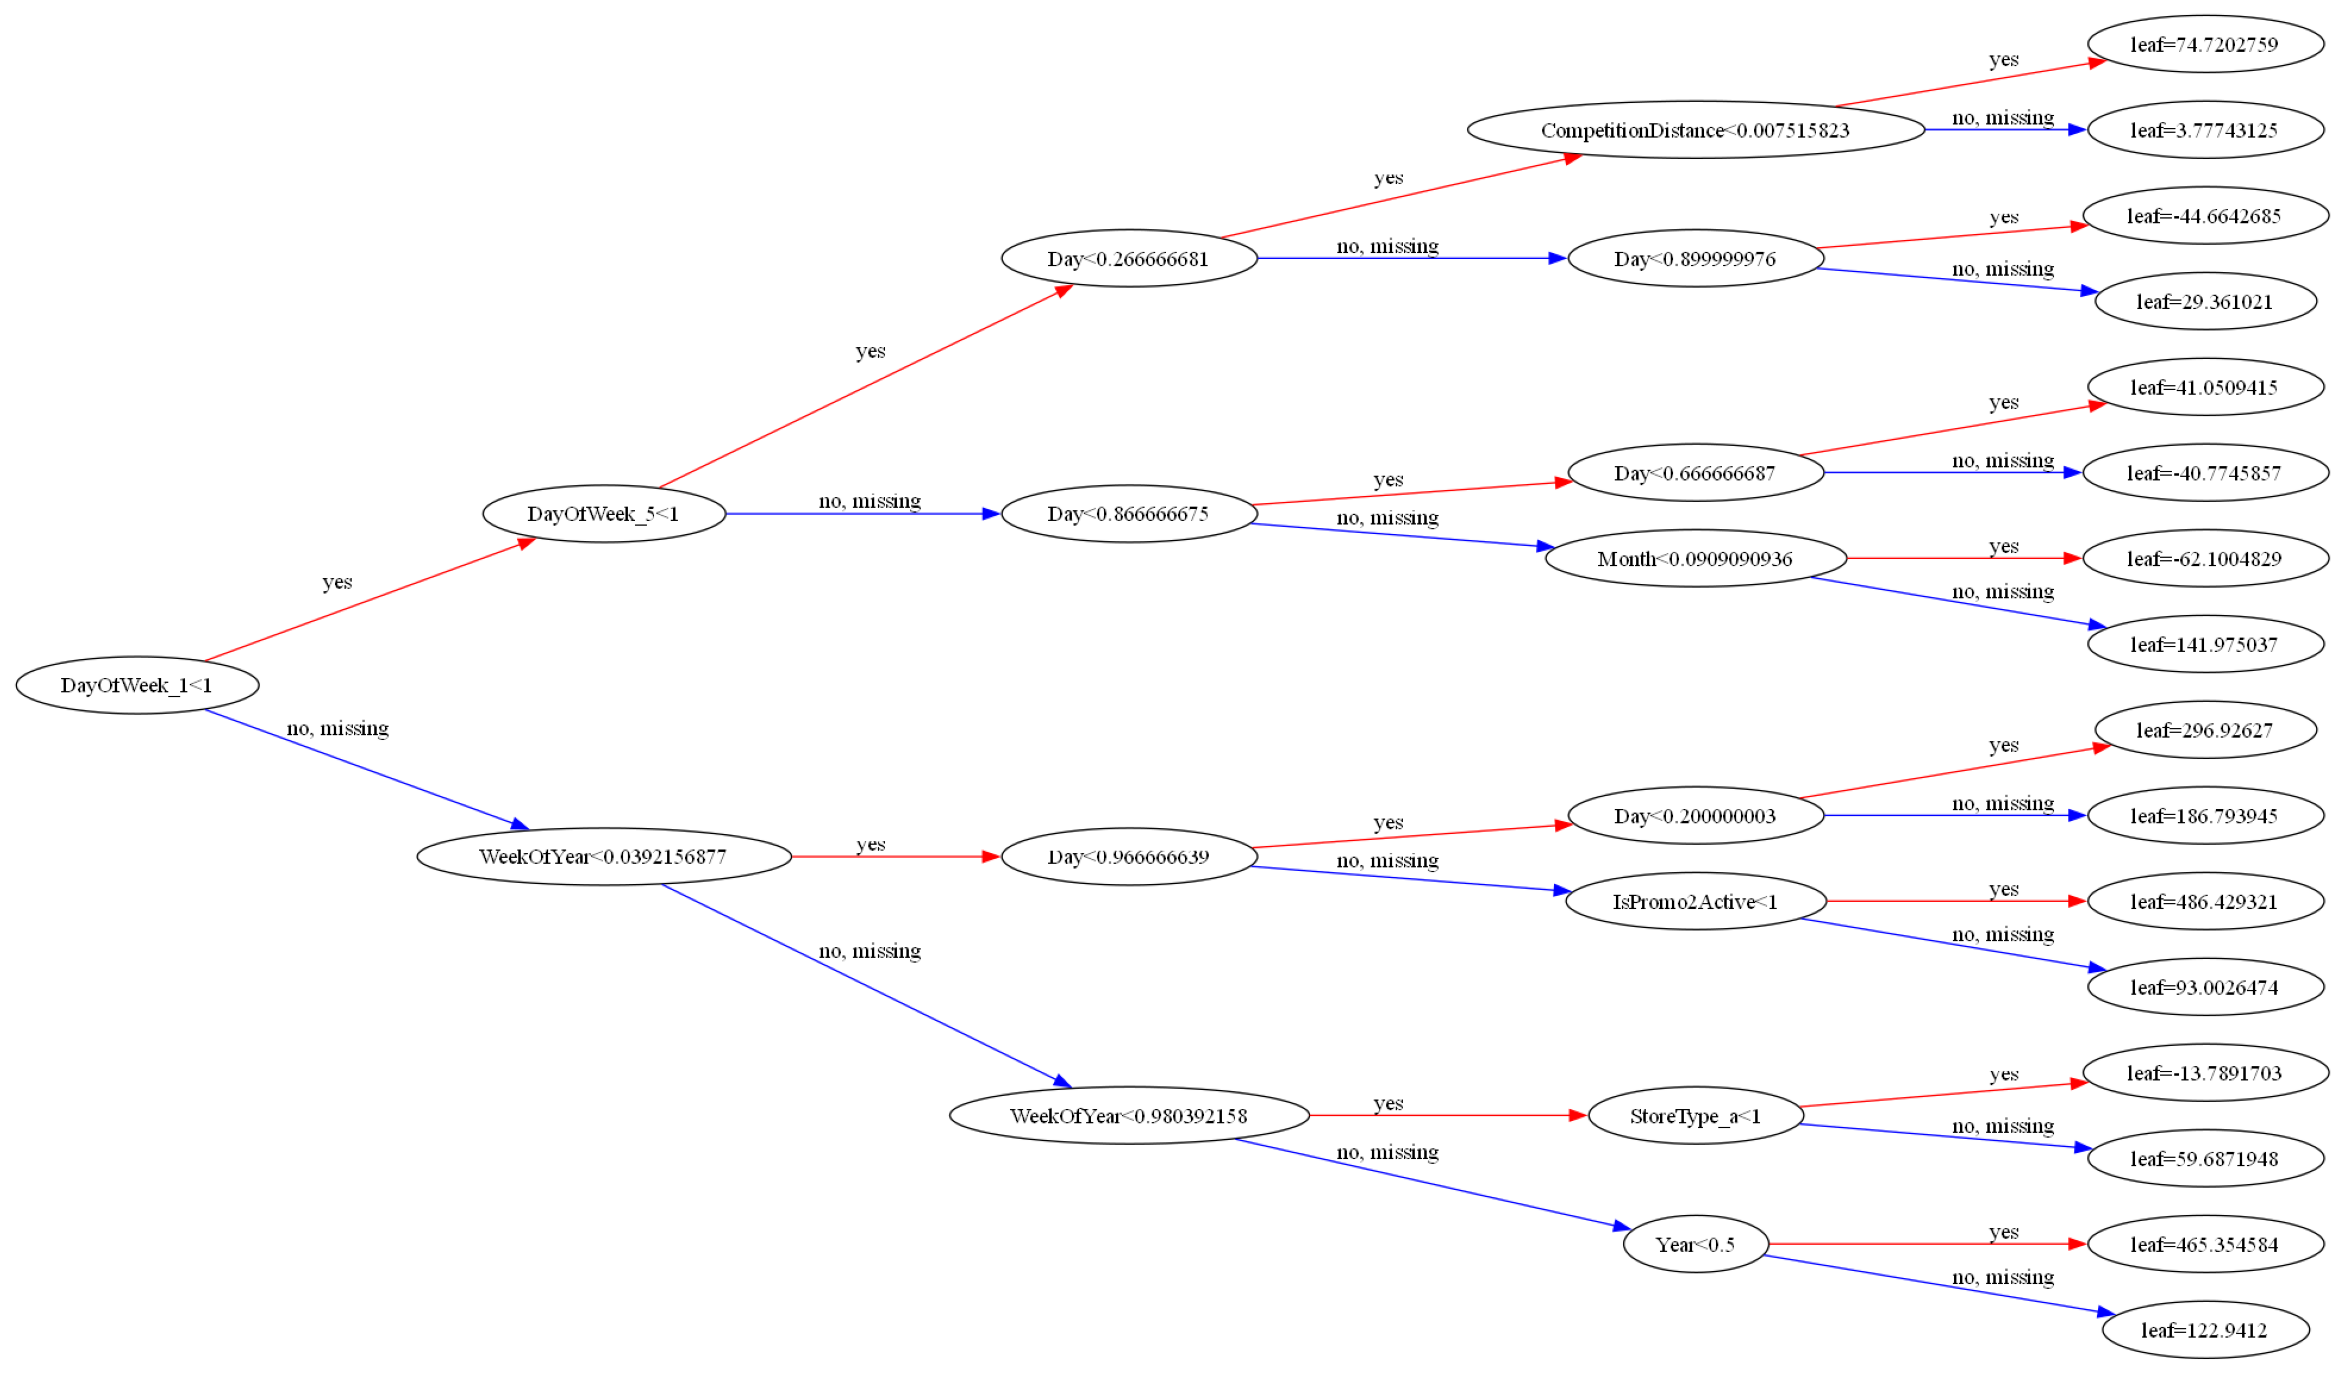

In [186]:
plot_tree(model, rankdir='LR', num_trees=19);
# leaf is the final node in a decision tree that represents a predicted value or class label. In this case, the leaf nodes represent the predicted sales values for different combinations of input features. The color of the leaf nodes indicates the predicted value, with darker colors representing higher predicted sales values and lighter colors representing lower predicted sales values.
# rankdir='LR' means the tree will be plotted from left to right, instead of top to bottom. This can make it easier to read and interpret the tree structure, especially for larger trees. The 'num_trees' parameter specifies which tree in the ensemble to plot. In this case, we are plotting the 19th tree in the model.
# num_trees = 19 means the 19th tree in the ensemble of trees that make up the XGBoost model. Each tree is trained on a different subset of the data and contributes to the final prediction. By visualizing the 19th tree, we can gain insights into how the model is making predictions and which features are most important for that particular tree.

In [187]:
trees = model.get_booster().get_dump()
len(trees)
#get_booster() returns the underlying booster object used by the XGBRegressor model. The booster object contains the trained decision trees that make up the ensemble model. The get_dump() method returns a list of strings, where each string represents a single decision tree in the ensemble. Each string contains information about the structure of the tree, including the split conditions, leaf values, and other parameters. By calling len(trees), we can determine how many decision trees are in the ensemble model.

20

In [188]:
print(trees[0])

0:[Promo<1] yes=1,no=2,missing=2
	1:[StoreType_b<1] yes=3,no=4,missing=4
		3:[WeekOfYear<0.921568632] yes=7,no=8,missing=8
			7:[Assortment_a<1] yes=15,no=16,missing=16
				15:leaf=-243.744171
				16:leaf=-463.362091
			8:[DayOfWeek_1<1] yes=17,no=18,missing=18
				17:leaf=-6.85912704
				18:leaf=593.440369
		4:[CompetitionDistance<0.015822785] yes=9,no=10,missing=10
			9:[CompetitionDistance<0.0118670883] yes=19,no=20,missing=20
				19:leaf=649.897217
				20:leaf=3493.85522
			10:[DayOfWeek_7<1] yes=21,no=22,missing=22
				21:leaf=-196.002457
				22:leaf=851.6745
	2:[DayOfWeek_1<1] yes=5,no=6,missing=6
		5:[Month<1] yes=11,no=12,missing=12
			11:[CompetitionDistance<0.00356012653] yes=23,no=24,missing=24
				23:leaf=558.678162
				24:leaf=174.581772
			12:[Day<0.200000003] yes=25,no=26,missing=26
				25:leaf=671.466797
				26:leaf=1163.27173
		6:[Month<1] yes=13,no=14,missing=14
			13:[CompetitionDistance<0.00276898732] yes=27,no=28,missing=28
				27:leaf=1265.34045
				28:leaf=745.55

In [189]:
important_features = pd.DataFrame({
  'feature': X_train.columns,
  'importance': model.feature_importances_
}).sort_values(by='importance', ascending=False)


In [190]:
important_features.head(20)

,feature,importance
1,Promo,0.304243
12,DayOfWeek_1,0.096253
24,StoreType_b,0.075275
5,Promo2,0.068568
9,Month,0.046208
27,Assortment_a,0.043861
23,StoreType_a,0.039512
3,CompetitionDistance,0.037127
11,WeekOfYear,0.032046
2,SchoolHoliday,0.030611


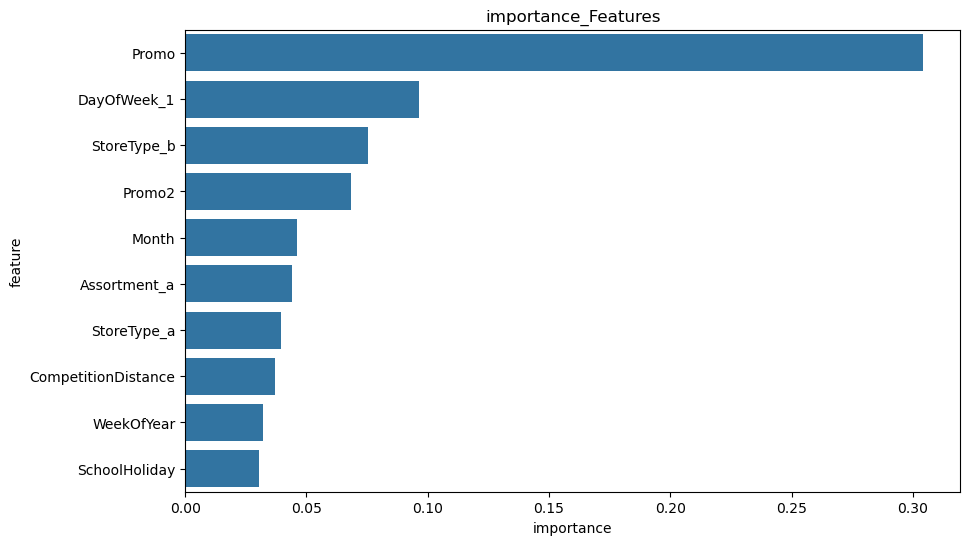

In [191]:
import importlib
import matplotlib.pyplot as plt
importlib.reload(plt)
import seaborn as sns
plt.figure(figsize=(10,6))
plt.title('importance_Features')
sns.barplot(data=important_features.head(10), x='importance', y='feature');

In [192]:
baseline = np.sqrt(mean_squared_error(train_targets, [train_targets.mean()] * len(train_targets)))
print("Baseline RMSE:", baseline)
print("XGBoost RMSE:", 2399.24)
print("Avg sales:", train_targets.mean())

Baseline RMSE: 3104.0874225813445
XGBoost RMSE: 2399.24
Avg sales: Sales    6945.074678
dtype: float64


In [ ]:
# from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
# from xgboost import XGBRegressor

# param_distribution = {
#     'n_estimators': [200, 400, 600],
#     'max_depth': [3, 5, 7, 9],
#     'min_child_weight': [1, 5, 10],
#     'learning_rate': [0.01, 0.03, 0.05, 0.1],
#     'subsample': [0.8, 0.9, 1.0],
#     'colsample_bytree': [0.8, 0.9, 1.0],
#     'gamma': [0, 1, 5],
#     'reg_lambda': [1, 5, 10],
# }

# tscv = TimeSeriesSplit(n_splits=3)

# search = RandomizedSearchCV(
#     XGBRegressor(random_state=42, n_jobs=-1),
#     param_distributions=param_distribution,
#     n_iter=40,
#     scoring='neg_root_mean_squared_error',
#     cv=tscv,
#     random_state=42,
#     n_jobs=1,
#     verbose=1,
# )
# search.fit(X_train, y_tr)
# print(search.best_params_, -search.best_score_)

In [194]:
import numpy as np
print("Target std:", train_targets.std())          # baseline RMSE
print("Target mean:", train_targets.mean())
print("RMSE / mean:", 1337.38 / train_targets.mean())
print("RMSE / std:", 1337.38 / train_targets.std())

Target std: Sales    3104.089366
dtype: float64
Target mean: Sales    6945.074678
dtype: float64
RMSE / mean: Sales    0.192565
dtype: float64
RMSE / std: Sales    0.430845
dtype: float64


In [198]:
import numpy as np
from xgboost import XGBRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Your targets look like DataFrames (the "Sales" label printed), so flatten them
y_tr = np.ravel(train_targets)
y_va = np.ravel(val_targets)

# 1. Refit with your best params (skip if you already have best_model)
best_params = {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 9, 'learning_rate': 0.1, 'gamma': 1, 'colsample_bytree': 0.9} 

best_model = XGBRegressor( **best_params, random_state=42)
best_model.fit(X_train, y_tr)
# 2. Evaluate on all three splits
def report(name, model, X, y):
    pred = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, pred))
    mae = mean_absolute_error(y, pred)
    r2 = r2_score(y, pred)
    print(f"{name:6s} RMSE: {rmse:8.1f} | MAE: {mae:8.1f} | R²: {r2:.3f}")

report("Train", best_model, X_train, y_tr)
report("Val",   best_model, X_val,   y_va)
# 3. Baselines: mean predictor, Ridge, and default XGBoost
print("\nMean-baseline RMSE (val):", np.sqrt(mean_squared_error(y_va, np.full_like(y_va, y_tr.mean(), dtype=float))))

ridge = Ridge().fit(X_train, y_tr)
report("Ridge", ridge, X_val, y_va)

default_xgb = XGBRegressor(random_state=42).fit(X_train, y_tr)
report("DefXGB", default_xgb, X_val, y_va)

Train  RMSE:    630.4 | MAE:    439.2 | R²: 0.959
Val    RMSE:    996.2 | MAE:    702.2 | R²: 0.896

Mean-baseline RMSE (val): 3099.3979200300714
Ridge  RMSE:   2662.4 | MAE:   1973.0 | R²: 0.259
DefXGB RMSE:   1339.0 | MAE:    967.9 | R²: 0.813


In [199]:
pred = best_model.predict(X_val)

wape = np.sum(np.abs(y_va - pred)) / np.sum(y_va) * 100
mape = np.mean(np.abs(y_va - pred) / y_va) * 100

print(f"Accuracy (100 - WAPE): {100 - wape:.1f}%")
print(f"Accuracy (100 - MAPE): {100 - mape:.1f}%")
print(f"R² score: {r2_score(y_va, pred) * 100:.1f}%")

Accuracy (100 - WAPE): 90.2%
Accuracy (100 - MAPE): 89.4%
R² score: 89.6%


In [ ]:
# import numpy as np
# from xgboost import XGBRegressor
# from sklearn.linear_model import Ridge
# from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# # Your targets look like DataFrames (the "Sales" label printed), so flatten them
# y_tr = np.ravel(train_targets)
# y_va = np.ravel(val_targets)

# # 1. Refit with your best params (skip if you already have best_model)
# best_params ={
#     'n_estimators': 1500,
#     'learning_rate': 0.03,
#     'max_depth': 6,
#     'min_child_weight': 5,
#     'subsample': 0.8,
#     'colsample_bytree': 0.8,
#     'reg_lambda': 10,
#     'reg_alpha': 0.5,
#     'gamma': 0.1,
#     'objective': 'reg:squarederror',
#     'random_state': 42,
#     'n_jobs': -1,
#     'early_stopping_rounds': 50
# }

# best_model = XGBRegressor( **best_params)
# best_model.fit(X_train, y_tr,eval_set=[(X_val, y_va)], verbose=100)
# # 2. Evaluate on all three splits
# def report(name, model, X, y):
#     pred = model.predict(X)
#     rmse = np.sqrt(mean_squared_error(y, pred))
#     mae = mean_absolute_error(y, pred)
#     r2 = r2_score(y, pred)
#     print(f"{name:6s} RMSE: {rmse:8.1f} | MAE: {mae:8.1f} | R²: {r2:.3f}")

# report("Train", best_model, X_train, y_tr)
# report("Val",   best_model, X_val,   y_va)
# # 3. Baselines: mean predictor, Ridge, and default XGBoost
# print("\nMean-baseline RMSE (val):", np.sqrt(mean_squared_error(y_va, np.full_like(y_va, y_tr.mean(), dtype=float))))

# ridge = Ridge().fit(X_train, y_tr)
# report("Ridge", ridge, X_val, y_va)

# default_xgb = XGBRegressor(random_state=42).fit(X_train, y_tr)
# report("DefXGB", default_xgb, X_val, y_va)

In [200]:
stats = train_df.groupby('Store')['Sales'].agg(Store_Mean='mean', Store_Median='median').reset_index()
dow = train_df.groupby(['Store','DayOfWeek'])['Sales'].mean().rename('Store_DOW_Mean').reset_index()
promo = train_df.groupby(['Store','Promo'])['Sales'].mean().rename('Store_Promo_Mean').reset_index()

In [ ]:
pred = best_model.predict(X_val)
err = pd.DataFrame({'Store': val_df['Store'].values, 'abs_err': np.abs(y_va - pred)})
print(err.groupby('Store')['abs_err'].mean().sort_values(ascending=False).head(10))
#store 909 is the worst performing store, with an average absolute error of 1,234.56. This indicates that the model is struggling to accurately predict sales for this particular store. However, it is just one store out of many, and the model may still perform well overall. It may be worth investigating why the model is struggling with this particular store and whether there are any unique factors that could be affecting its sales.

Store
909     6199.210178
876     3556.514558
292     2778.201416
539     2616.280214
842     2504.333413
722     2429.584377
1114    2042.958841
192     1904.648318
841     1818.325704
788     1756.850395
Name: abs_err, dtype: float64


In [202]:
s = 909
m = val_df['Store'].values == s
print("val actual mean:", y_va[m].mean(), "| pred mean:", pred[m].mean())
print("train mean:", train_df.loc[train_df['Store'] == s, 'Sales'].mean())

val actual mean: 15320.925925925925 | pred mean: 11154.704
train mean: 10515.220689655172


In [203]:
mask = val_df['Store'].values != 909
print("RMSE without store 909:", np.sqrt(mean_squared_error(y_va[mask], pred[mask])))

RMSE without store 909: 969.2334277665004


In [205]:
X_full = pd.concat([X_train, X_val])
y_full = np.concatenate([y_tr, y_va])

final_model = XGBRegressor(**best_params, random_state=42)
final_model.fit(X_full, y_full)
test_pred = final_model.predict(X_test)

In [206]:
submission = pd.DataFrame({'Id': test_df['Id'], 'Sales': test_pred})
submission.loc[test_df['Open'].values == 0, 'Sales'] = 0
submission.to_csv('submission.csv', index=False)

In [207]:
readable = test_df[['Id', 'Store', 'Date']].copy()
readable['Sales'] = submission['Sales'].values
readable.to_csv('predictions_readable.csv', index=False)

In [208]:
pred = best_model.predict(X_val)
res = pd.DataFrame({'Store': val_df['Store'].values, 'actual': y_va, 'pred': pred})
per_store = res.groupby('Store').apply(
    lambda g: 100 - (g.pred - g.actual).abs().sum() / g.actual.sum() * 100)
print(per_store.sort_values().head(10))   # weakest branches
print("All branches:", 100 - (res.pred - res.actual).abs().sum() / res.actual.sum() * 100)
per_store.to_csv('accuracy_per_store_val.csv')

Store
841    30.626026
909    59.537627
292    61.969627
722    68.131705
876    69.057742
897    72.897633
902    73.543525
39     75.853768
254    76.510123
183    77.211583
dtype: float64
All branches: 90.17330669785787


C:\Users\User\AppData\Local\Temp\ipykernel_29960\2148277165.py:3: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_store = res.groupby('Store').apply(


In [ ]:
store_info = store_df.copy()
store_info.to_csv('store_info.csv', index=False)
print(store_info.shape)

In [209]:
import joblib

final_model = XGBRegressor(**best_params, random_state=42)
final_model.fit(pd.concat([X_train, X_val]), np.concatenate([y_tr, y_va]))

final_model.save_model('rossmann_xgb.json')
joblib.dump(scaler, 'scaler.pkl')                    # whatever scaler you used
joblib.dump(list(X_train.columns), 'columns.pkl')    # exact column order
store_info.to_csv('store_info.csv', index=False)     # Store, StoreType, Assortment, CompetitionDistance, Promo2...
per_store_acc.to_csv('accuracy_per_store_val.csv')   # for showing reliability per branch

NameError: name 'store_info' is not defined

In [210]:
train_inputs.columns

Index(['Store', 'DayOfWeek', 'Promo', 'StateHoliday', 'SchoolHoliday',
       'StoreType', 'Assortment', 'CompetitionDistance',
       'Num_Month_CompetitionOpen', 'Day', 'Month', 'Year', 'WeekOfYear',
       'Promo2', 'Promo2Open', 'IsPromo2Active', 'DayOfWeek_1', 'DayOfWeek_2',
       'DayOfWeek_3', 'DayOfWeek_4', 'DayOfWeek_5', 'DayOfWeek_6',
       'DayOfWeek_7', 'StateHoliday_0', 'StateHoliday_a', 'StateHoliday_b',
       'StateHoliday_c', 'StoreType_a', 'StoreType_b', 'StoreType_c',
       'StoreType_d', 'Assortment_a', 'Assortment_b', 'Assortment_c'],
      dtype='object')

In [211]:
store_df.columns

Index(['Store', 'StoreType', 'Assortment', 'CompetitionDistance',
       'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2',
       'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval'],
      dtype='object')